# Cuaderno B: máscaras con SAM 2 (etiquetado offline)

Este cuaderno es PyTorch puro (no se importa TensorFlow ni Keras). SAM 2 se usa **solo como herramienta de etiquetado offline**; no entra a la demo final.

Flujo: configuración, instalación, función de segmentación, piloto visual (30 imágenes de val), lote completo, posproceso con OpenCV, control de calidad recalibrado con val, comparación visual contra GrabCut y empaquetado en `masks_sam2.zip`.

## 0. Configuración

Ahora vamos a fijar las constantes que editas tú. Esta celda solo contiene constantes, así que puedes volver a ejecutarla sin riesgo (por ejemplo, para fijar los umbrales de la sección 6 o cambiar `PROMPT`).

- `PROMPT`: `'P3'` por defecto; cámbialo a `'P1'` si gana P1 en el piloto (sección 3).
- `AREA_MIN`, `AREA_MAX`, `BORDE_MAX`: se dejan en `None` y los fijas **después** de ver las cuadrículas de la sección 6. No se copian los umbrales de GrabCut ($0.02$, $0.35$, $0.30$): se recalibran para SAM 2 usando solo val.

In [28]:
# --- Rutas (todas relativas a ROOT) ---
ROOT = '/content/drive/MyDrive/sylfish'                 # raíz de los datos en Drive
SAM2_DIR = f'{ROOT}/sam2'                               # entradas del cuaderno A y salidas intermedias
P_SPLITS = f'{ROOT}/data/splits/splits.csv'             # partición oficial
PROC = f'{ROOT}/data/processed'                         # mask_qc.csv de GrabCut
P_QC_GC = f'{PROC}/mask_qc.csv'                         # control de calidad de GrabCut
P_MASKS_GC = f'{ROOT}/data/masks.zip'                   # máscaras GrabCut
ZIP_IMG = f'{ROOT}/data/raw/SylFishBD_IMAGE.zip'        # imágenes originales (solo existe el zip)
DIR_IMG_LOCAL = '/content/sylfish_images'               # carpeta local de extracción
TAB = f'{ROOT}/reports/tables'                          # tablas con prefijo sam2_
FIG = f'{ROOT}/reports/figures'                         # figuras con prefijo sam2_
DRIVE_RAW = f'{SAM2_DIR}/masks_raw'                     # máscaras crudas del lote (Drive)
DRIVE_FINAL = f'{SAM2_DIR}/masks_sam2'                      # máscaras posprocesadas (Drive)
LOCAL_RAW = '/content/sam2_raw'                         # disco local de Colab (rápido) para las crudas
LOCAL_FINAL = '/content/masks_sam2'                     # disco local de Colab para las finales

# --- Reproducibilidad e integridad ---
SEMILLA = 42                                            # semilla global
MD5_SPLITS = '5b174a510317656566c44916ff8da4a7'         # MD5 esperado de splits.csv

# --- Modelo SAM 2.1 (nombres verificados en el README oficial de facebookresearch/sam2) ---
CKPT_NAME = 'sam2.1_hiera_small.pt'                     # checkpoint pequeño; alternativas: tiny, base_plus, large
CKPT_URL = 'https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt'
MODEL_CFG = 'configs/sam2.1/sam2.1_hiera_s.yaml'        # ruta relativa al paquete sam2 (small = _s; tiny = _t; base_plus = _b+; large = _l)
# Si cambias de tamaño, cambia CKPT_NAME, CKPT_URL y MODEL_CFG juntos (la URL cambia solo en el nombre del archivo).

# --- Precisión numérica ---
# La T4 (capacidad 7.5) no tiene bfloat16 nativo, y el ejemplo del README usa bfloat16. Usamos fp32 por defecto:
# es lo más estable y el modelo small es liviano. 'fp16' activa autocast float16 (más rápido, pero hay que revisar a ojo).
PRECISION = 'fp32'                                      # 'fp32' o 'fp16'

# --- Prompts ---
PROMPT = 'P3'                                           # 'P3' (caja U-Net v1 + punto) o 'P1' (caja fija); se cambia a 'P1' si gana en el piloto
MARGEN_P1 = 0.05                                        # P1: la imagen completa con margen 0.05 por lado -> [25, 25, 475, 475]
AMPLIAR_P3 = 0.05                                       # P3: caja de la U-Net v1 ampliada 5 % por lado

# --- Orden de procesamiento y control del lote ---
SPLITS_ORDEN = ['val', 'train', 'test']                 # si falta tiempo se procesan val y train primero
FORZAR_LOTE = False                                     # True = continuar al lote aunque el piloto no llegue a 18/30 (bajo tu responsabilidad)

# --- Posproceso ---
APERTURA_K = 0                                          # 0 = sin apertura (para no borrar aletas finas); 3 = apertura 3x3
REHACER_POSPROCESO = False                              # True = rehacer todo el posproceso si cambiaste parámetros (ponlo en False al terminar)

# --- Control de calidad (se fijan DESPUÉS de ver las cuadrículas de la sección 6) ---
BANDA_BORDE = 5                                         # grosor en px de la banda del borde de la imagen
AREA_MIN = 0.02                                         # fracción mínima de área; ej.: 0.0X (se fija con val)
AREA_MAX = 0.35                                         # fracción máxima de área
BORDE_MAX = 0.08                                        # fracción máxima ocupada en la banda del borde
FRAC_CC_MIN = None                                      # OPCIONAL: fracción mínima de la componente mayor (None = no se usa)

## 1. Instalación y entorno

Ahora vamos a instalar SAM 2 desde GitHub, siguiendo el README oficial (`git clone` y `pip install -e .`). Requisitos del README: Python $\geq 3.10$ y PyTorch $\geq 2.5.1$ (torchvision $\geq 0.20.1$). Si el `pip` intentara reinstalar PyTorch, reinicia el entorno y vuelve a ejecutar desde aquí. La extensión CUDA opcional puede fallar al compilar sin afectar nada (el setup continúa por defecto); verás avisos que se pueden ignorar.

In [2]:
!test -d /content/sam2_repo || git clone -q https://github.com/facebookresearch/sam2.git /content/sam2_repo
!pip install -q -e /content/sam2_repo

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done


Ahora vamos a importar todas las librerías en una sola celda. Añadimos el repositorio clonado al `sys.path` para que `import sam2` funcione en esta misma sesión sin reiniciar.

In [3]:
import sys  # rutas de módulos
sys.path.insert(0, '/content/sam2_repo')  # permite importar sam2 recién instalado sin reiniciar el kernel
import os  # rutas y archivos
import io  # buffers en memoria
import json  # parámetros y reportes
import time  # cronometrar la inferencia
import math  # redondeos de cuadrículas
import random  # semilla y muestreos
import shutil  # copias de archivos
import hashlib  # MD5 de splits.csv
import zipfile  # leer masks.zip y escribir masks_sam2.zip
import urllib.request  # descargar el checkpoint
import contextlib  # contexto nulo para fp32
import numpy as np  # arreglos
import pandas as pd  # tablas
import cv2  # lectura de imágenes y posproceso con OpenCV
import torch  # PyTorch (SAM 2)
import matplotlib.pyplot as plt  # figuras y cuadrículas
from tqdm.auto import tqdm  # barras de progreso
from google.colab import drive  # montar Google Drive
from sam2.build_sam import build_sam2  # constructor del modelo SAM 2
from sam2.sam2_image_predictor import SAM2ImagePredictor  # predictor para imágenes

Ahora vamos a definir las utilidades que se reutilizan en todo el cuaderno: escritura atómica (archivo temporal más `os.replace`), lectura de imágenes en RGB, dibujo de contornos y el motor reanudable por bloques. Esta celda solo define funciones.

In [4]:
def stem_de(fp):  # nombre de archivo sin extensión (único en el dataset)
    return os.path.splitext(os.path.basename(fp))[0]

def listar_archivos(d):  # conjunto de nombres de archivo de un directorio (vacío si no existe)
    return set(os.listdir(d)) if os.path.isdir(d) else set()

def guardar_bytes_atomico(path, datos):  # escribe en .tmp y reemplaza
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + '.tmp'
    with open(tmp, 'wb') as f:
        f.write(datos)
    os.replace(tmp, path)

def guardar_png_atomico(path, arr):  # PNG atómico desde un arreglo
    ok, buf = cv2.imencode('.png', arr)
    assert ok, f'No se pudo codificar PNG: {path}'
    guardar_bytes_atomico(path, buf.tobytes())

def guardar_csv_atomico(df, path):  # CSV atómico
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + '.tmp'
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)

def guardar_json_atomico(obj, path):  # JSON atómico
    guardar_bytes_atomico(path, json.dumps(obj, indent=2, ensure_ascii=False).encode('utf-8'))

def copiar_atomico(origen, destino):  # copia local -> Drive vía archivo temporal
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    tmp = destino + '.tmp'
    shutil.copyfile(origen, tmp)
    os.replace(tmp, destino)

def leer_rgb(fp):  # imagen RGB uint8 500x500x3 (cv2 lee BGR: se convierte)
    img = cv2.imread(ruta_img(fp), cv2.IMREAD_COLOR)
    assert img is not None, f'No se pudo leer la imagen: {fp}'
    assert img.shape == (500, 500, 3), f'Tamaño inesperado {img.shape} en {fp}'
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def leer_png_gris(path):  # máscara PNG en escala de grises
    m = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    assert m is not None, f'No se pudo leer: {path}'
    return m

BASES = {'raw': (LOCAL_RAW, DRIVE_RAW), 'final': (LOCAL_FINAL, DRIVE_FINAL)}  # (local, Drive) por tipo de máscara

def leer_mascara(tipo, carpeta, stem):  # lee la máscara local si existe; si no, la de Drive
    loc, dri = BASES[tipo]
    p = f'{loc}/{carpeta}/{stem}.png'
    if not os.path.exists(p):
        p = f'{dri}/{carpeta}/{stem}.png'
    return leer_png_gris(p)

def contorno_sobre(img_rgb, mask, color, grosor=2):  # dibuja el contorno de la máscara sobre la imagen
    out = img_rgb.copy()
    cs, _ = cv2.findContours((mask > 127).astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cs, -1, color, grosor)
    return out

def superponer(img_rgb, mask, color=(255, 0, 0), alpha=0.45):  # relleno translúcido más contorno
    out = img_rgb.copy()
    sel = mask > 127
    out[sel] = ((1 - alpha) * out[sel] + alpha * np.array(color)).astype(np.uint8)
    return contorno_sobre(out, mask, color, 1)

def cuadricula_mascaras(df_sel, tipo, titulo, archivo, ncols=6, extra=None):  # cuadrícula de imágenes con la máscara superpuesta
    if len(df_sel) == 0:
        print(f'{titulo}: no hay imágenes para mostrar')
        return
    nrows = math.ceil(len(df_sel) / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.3 * nrows), squeeze=False)
    for ax in axs.ravel():
        ax.axis('off')
    for ax, r in zip(axs.ravel(), df_sel.itertuples(index=False)):
        ax.imshow(superponer(leer_rgb(r.filepath), leer_mascara(tipo, r.carpeta, r.stem)))
        ax.set_title(extra(r) if extra else r.stem, fontsize=8)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.savefig(f'{FIG}/{archivo}', dpi=90)
    plt.show()
    plt.close(fig)

# --- Motor reanudable por bloques (se usa en el lote y en el posproceso) ---
def leer_registro(path, columnas):  # {filepath: {columna: valor}} desde un CSV (vacío si no existe o es inconsistente)
    if not os.path.exists(path):
        return {}
    df = pd.read_csv(path)
    if not set(['filepath'] + columnas) <= set(df.columns):
        print(f'AVISO: {path} no tiene las columnas esperadas; se ignora')
        return {}
    df = df.dropna(subset=columnas)
    return {r['filepath']: {c: r[c] for c in columnas} for r in df.to_dict('records')}

def escribir_registro(reg, path, columnas):  # escribe el registro de forma atómica
    df = pd.DataFrame([{'filepath': fp, **v} for fp, v in reg.items()], columns=['filepath'] + columnas)
    guardar_csv_atomico(df, path)

def procesar_por_bloques(lote, fn_item, dir_local, dir_drive, csv_local, csv_drive, columnas, desc, cada=250, forzar=False):
    # lote: DataFrame con filepath, split, carpeta, stem, ordenado por (split, carpeta).
    # fn_item(fila) -> (arreglo_png, {columna: valor}). Escribe PNG en local y copia a Drive por bloque (split, clase).
    reg_lo = leer_registro(csv_local, columnas)  # registro local (journal)
    reg_dr = leer_registro(csv_drive, columnas)  # registro en Drive
    reg = {}                                     # registro de lo ya hecho o recién calculado
    plan = []
    for (sp, cl), g in lote.groupby(['split', 'carpeta'], sort=False):
        lo = listar_archivos(f'{dir_local}/{cl}')
        dr = listar_archivos(f'{dir_drive}/{cl}')
        pend = []
        for r in g.itertuples(index=False):
            png = f'{r.stem}.png'
            if (not forzar) and png in lo and r.filepath in reg_lo:      # hecho en local y registrado
                reg[r.filepath] = reg_lo[r.filepath]
            elif (not forzar) and png in dr and r.filepath in reg_dr:    # hecho en Drive y registrado
                reg[r.filepath] = reg_dr[r.filepath]
            else:
                pend.append(r)
        plan.append((sp, cl, g, pend))
    total_pend = sum(len(p[3]) for p in plan)
    print(f'{desc}: total {len(lote)}, ya hechas {len(lote) - total_pend}, pendientes {total_pend}')
    pbar = tqdm(total=total_pend, desc=desc)
    for sp, cl, g, pend in plan:
        recalc = set()
        for k, r in enumerate(pend, 1):
            arr, vals = fn_item(r)
            guardar_png_atomico(f'{dir_local}/{cl}/{r.stem}.png', arr)
            reg[r.filepath] = vals
            recalc.add(f'{r.stem}.png')
            pbar.update(1)
            if k % cada == 0:
                escribir_registro(reg, csv_local, columnas)               # journal local cada N imágenes
        if pend:
            escribir_registro(reg, csv_local, columnas)
        lo = listar_archivos(f'{dir_local}/{cl}')
        dr = listar_archivos(f'{dir_drive}/{cl}')
        n_cop = 0
        for r in g.itertuples(index=False):                                 # copia a Drive por bloque, saltando lo existente
            png = f'{r.stem}.png'
            if png in lo and r.filepath in reg and ((png not in dr) or (png in recalc)):
                copiar_atomico(f'{dir_local}/{cl}/{png}', f'{dir_drive}/{cl}/{png}')
                n_cop += 1
        if pend or n_cop:
            unir = dict(reg_dr)
            unir.update(reg)                                                # conserva entradas de otros splits ya en Drive
            escribir_registro(unir, csv_drive, columnas)
            reg_dr = unir
    pbar.close()
    return reg

def verificar_config(ruta, cfg, nombre, sobrescribir=False):  # evita mezclar resultados de configuraciones distintas
    cfg_json = json.loads(json.dumps(cfg))
    if os.path.exists(ruta) and not sobrescribir:
        with open(ruta) as f:
            previa = json.load(f)
        assert previa == cfg_json, (f'La configuración de {nombre} cambió respecto a la guardada en {ruta}.\n'
                                    f'Antes: {previa}\nAhora: {cfg_json}\n'
                                    'Revierte el cambio o elimina los resultados y ese archivo para empezar de nuevo.')
    guardar_json_atomico(cfg_json, ruta)

Ahora vamos a preparar el entorno: comprobar que TensorFlow no está cargado, fijar semillas, verificar la GPU, montar Drive, verificar el MD5 de `splits.csv`, descargar el checkpoint y construir el predictor. Si la GPU no aparece, cambia el tipo de entorno a T4.

In [5]:
assert 'tensorflow' not in sys.modules, 'TensorFlow está cargado: reinicia el entorno (TF y PyTorch no pueden compartir la GPU)'  # sin TF
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA); torch.cuda.manual_seed_all(SEMILLA)  # semillas
assert torch.cuda.is_available(), 'No hay GPU: Entorno de ejecución > Cambiar tipo de entorno > T4'  # exige GPU
DEVICE = 'cuda'  # dispositivo de cómputo
print('GPU:', torch.cuda.get_device_name(0), '| capacidad', torch.cuda.get_device_capability(0), '| torch', torch.__version__)
print('Precisión elegida:', PRECISION, '(la T4 no tiene bfloat16 nativo)')

drive.mount('/content/drive')  # monta Drive
assert os.path.isdir(ROOT), f'No existe {ROOT}'  # la raíz debe existir
for d in (SAM2_DIR, TAB, FIG, f'{SAM2_DIR}/piloto/P1', f'{SAM2_DIR}/piloto/P3', DRIVE_RAW, DRIVE_FINAL, LOCAL_RAW, LOCAL_FINAL):
    os.makedirs(d, exist_ok=True)  # carpetas de salida

with open(P_SPLITS, 'rb') as f:
    md5 = hashlib.md5(f.read()).hexdigest()  # MD5 de splits.csv
assert md5 == MD5_SPLITS, f'MD5 de splits.csv distinto: {md5}'  # integridad de los splits
splits = pd.read_csv(P_SPLITS)  # tabla maestra
assert len(splits) == 8975 and splits['filepath'].is_unique, 'splits.csv inesperado'
splits['carpeta'] = splits['filepath'].str.split('/').str[0]  # carpeta de clase según filepath
splits['stem'] = splits['filepath'].map(stem_de)  # nombre sin extensión
assert splits['stem'].is_unique, 'Hay stems repetidos: no se puede emparejar por stem'
print('splits:', splits['split'].value_counts().to_dict(), '| carpetas distintas de la columna clase:', int((splits['carpeta'] != splits['clase']).sum()))

CKPT_LOCAL = f'/content/checkpoints/{CKPT_NAME}'  # checkpoint en disco local
if not os.path.exists(CKPT_LOCAL):
    os.makedirs(os.path.dirname(CKPT_LOCAL), exist_ok=True)
    urllib.request.urlretrieve(CKPT_URL, CKPT_LOCAL + '.tmp')  # descarga a temporal
    os.replace(CKPT_LOCAL + '.tmp', CKPT_LOCAL)  # atómico
print('Checkpoint:', CKPT_LOCAL, f'{os.path.getsize(CKPT_LOCAL) / 1e6:.0f} MB')

sam2_model = build_sam2(MODEL_CFG, CKPT_LOCAL, device=DEVICE)  # construye SAM 2 y carga pesos
predictor = SAM2ImagePredictor(sam2_model)  # predictor de imágenes
assert 'tensorflow' not in sys.modules  # sigue sin TF
print('SAM 2 listo.')

GPU: Tesla T4 | capacidad (7, 5) | torch 2.14.1+cu130
Precisión elegida: fp32 (la T4 no tiene bfloat16 nativo)
Mounted at /content/drive
splits: {'train': 6246, 'test': 1370, 'val': 1359} | carpetas distintas de la columna clase: 0
Checkpoint: /content/checkpoints/sam2.1_hiera_small.pt 184 MB


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


SAM 2 listo.


Ahora vamos a extraer las imágenes originales a disco local. En Drive solo existe el zip `data/raw/SylFishBD_IMAGE.zip` (no hay carpeta `images/`). Indexamos por el nombre de archivo sin extensión (`stem`, único en el dataset), así no dependemos de cómo esté organizado el zip por dentro.

In [6]:
marca = f'{DIR_IMG_LOCAL}/.listo'                                  # se escribe al terminar la extracción
if not os.path.exists(marca):                                       # extrae una sola vez por sesión (~420 MB)
    with zipfile.ZipFile(ZIP_IMG) as zf:
        zf.extractall(DIR_IMG_LOCAL)
    open(marca, 'w').close()
IMG_INDEX = {os.path.splitext(f)[0]: os.path.join(r, f)             # stem -> ruta local
             for r, _, fs in os.walk(DIR_IMG_LOCAL) for f in fs if f.lower().endswith(('.jpg', '.jpeg', '.png'))}

def ruta_img(fp):                                                   # ruta local de una imagen a partir de su filepath
    return IMG_INDEX[os.path.splitext(os.path.basename(fp))[0]]

print(len(IMG_INDEX), 'imágenes indexadas (esperado: 9075)')

9075 imágenes indexadas (esperado: 9075)


## 2. Función de segmentación

Ahora vamos a cargar las entradas que dejó el cuaderno A: `prompts.csv` (caja y centroide de la U-Net v1) y `muestra_val.csv` (30 imágenes de val). Cruzamos siempre por `filepath`. A la muestra le asignamos un **id de 1 a 30** (aleatoria 1 a 15, peor 16 a 23, descartada 24 a 30) que se usa igual en todas las figuras y tablas.

In [7]:
prompts = pd.read_csv(f'{SAM2_DIR}/prompts.csv')  # prompts de la U-Net v1 (cuaderno A)
assert prompts['filepath'].is_unique, 'prompts.csv tiene filepath repetidos'
assert set(prompts['filepath']) <= set(splits['filepath']), 'prompts.csv tiene filepath que no están en splits.csv'
prompts['unet_vacia'] = prompts['unet_vacia'].astype(str).str.lower().isin(['true', '1'])  # a booleano real
PROM = {r['filepath']: r for r in prompts.to_dict('records')}  # acceso por filepath
print('prompts.csv:', len(prompts), 'filas | unet_vacia:', int(prompts['unet_vacia'].sum()))

muestra = pd.read_csv(f'{SAM2_DIR}/muestra_val.csv')  # 30 imágenes de val (cuaderno A)
assert len(muestra) == 30 and muestra['filepath'].is_unique, 'muestra_val.csv debe tener 30 filepath únicos'
assert muestra['estrato'].value_counts().to_dict() == {'aleatoria': 15, 'peor': 8, 'descartada': 7}, 'estratos inesperados'
assert set(muestra['filepath']) <= set(splits.loc[splits['split'] == 'val', 'filepath']), 'la muestra debe ser de val'
assert set(muestra['filepath']) <= set(PROM), 'faltan prompts para imágenes de la muestra'
orden_est = {'aleatoria': 0, 'peor': 1, 'descartada': 2}  # orden fijo de estratos
muestra = muestra.assign(_o=muestra['estrato'].map(orden_est)).sort_values('_o', kind='stable').drop(columns='_o').reset_index(drop=True)
muestra['id'] = np.arange(1, 31)  # id 1..30, el mismo en todas las figuras y en el CSV
muestra['stem'] = muestra['filepath'].map(stem_de)
muestra['carpeta'] = muestra['filepath'].str.split('/').str[0]
print(muestra.groupby('estrato')['id'].agg(['min', 'max', 'count']))

prompts.csv: 8975 filas | unet_vacia: 0
            min  max  count
estrato                    
aleatoria     1   15     15
descartada   24   30      7
peor         16   23      8


Ahora vamos a definir `segmentar` y los dos prompts. Trampas que cuidamos:

- **BGR vs RGB**: `cv2.imread` devuelve BGR; SAM 2 espera una imagen HWC `uint8` en RGB (`leer_rgb` ya convierte).
- **Caja en `xyxy`**, no `xywh`: $[x_1, y_1, x_2, y_2]$. El CSV trae $(u_x, u_y, u_w, u_h)$, que hay que convertir.
- **Coordenadas en 500 px**, no en 256 (las máscaras de baja resolución de 256 px no se usan).
- **El `score` mide qué tan bien delimitada está una región, no si es el pez**: puede preferir el plato o la mesa. Por eso se califica a ojo.

**P1**: caja fija de la imagen completa con margen $0.05$, es decir $[25, 25, 475, 475]$, independiente de la U-Net y de GrabCut.

**P3**: caja de la U-Net v1 ampliada 5 % por lado, más un punto positivo en el centroide $(u_{cx}, u_{cy})$:
$$x_1 = u_x - 0.05\,u_w,\quad y_1 = u_y - 0.05\,u_h,\quad x_2 = u_x + u_w + 0.05\,u_w,\quad y_2 = u_y + u_h + 0.05\,u_h,$$
recortada a $[0, 500]$. Si `unet_vacia` es verdadero, P3 cae al prompt P1 y se anota `uso_respaldo = True`.

In [8]:
CAJA_P1 = [500 * MARGEN_P1, 500 * MARGEN_P1, 500 * (1 - MARGEN_P1), 500 * (1 - MARGEN_P1)]  # [25, 25, 475, 475] en xyxy
assert CAJA_P1 == [25.0, 25.0, 475.0, 475.0], CAJA_P1

def contexto_inferencia():  # fp32 sin autocast, o autocast float16
    if PRECISION == 'fp16':
        return torch.autocast('cuda', dtype=torch.float16)
    return contextlib.nullcontext()

def segmentar(img_rgb, caja_xyxy=None, punto=None):  # devuelve (máscara uint8 {0,255} 500x500, score, n_candidatas)
    assert img_rgb.ndim == 3 and img_rgb.shape[2] == 3 and img_rgb.dtype == np.uint8, 'se espera HWC RGB uint8'
    assert caja_xyxy is not None or punto is not None, 'hace falta al menos un prompt'
    pc = pl = bx = None
    if punto is not None:  # punto positivo (x, y) en píxeles de la imagen de 500
        pc = np.array([[punto[0], punto[1]]], dtype=np.float32)
        pl = np.array([1], dtype=np.int32)
    if caja_xyxy is not None:  # caja [x1, y1, x2, y2] en píxeles de la imagen de 500
        bx = np.array(caja_xyxy, dtype=np.float32)
    with torch.inference_mode(), contexto_inferencia():
        predictor.set_image(img_rgb)  # calcula los embeddings de la imagen
        masks, scores, _ = predictor.predict(point_coords=pc, point_labels=pl, box=bx, multimask_output=True)
    if masks.ndim == 2:
        masks, scores = masks[None], np.atleast_1d(scores)
    k = int(np.argmax(scores))  # candidata de mayor score
    m = ((masks[k] > 0.5).astype(np.uint8)) * 255  # binarizar a {0,255}
    assert m.shape == img_rgb.shape[:2], f'forma de máscara inesperada {m.shape}'
    return m, float(scores[k]), int(len(scores))

def construir_prompt(fp, prompt):  # (caja_xyxy, punto, uso_respaldo) según el prompt
    if prompt == 'P1':
        return CAJA_P1, None, False
    assert prompt == 'P3', f'prompt desconocido: {prompt}'
    r = PROM.get(fp)  # cruce por filepath
    assert r is not None, f'{fp} no está en prompts.csv'
    claves = ['ux', 'uy', 'uw', 'uh', 'ucx', 'ucy']
    if r['unet_vacia'] or any(pd.isna(r[c]) for c in claves):  # U-Net v1 sin caja: respaldo P1
        return CAJA_P1, None, True
    x1 = max(0.0, r['ux'] - AMPLIAR_P3 * r['uw'])
    y1 = max(0.0, r['uy'] - AMPLIAR_P3 * r['uh'])
    x2 = min(500.0, r['ux'] + r['uw'] + AMPLIAR_P3 * r['uw'])
    y2 = min(500.0, r['uy'] + r['uh'] + AMPLIAR_P3 * r['uh'])
    return [x1, y1, x2, y2], (float(r['ucx']), float(r['ucy'])), False

def segmentar_fila(fp, prompt):  # lee, segmenta y mide el tiempo del modelo (sin lectura de Drive)
    img = leer_rgb(fp)
    caja, punto, resp = construir_prompt(fp, prompt)
    t0 = time.perf_counter()
    m, sc, n = segmentar(img, caja, punto)
    torch.cuda.synchronize()
    return m, sc, n, resp, time.perf_counter() - t0

Ahora vamos a comprobar la función con **una** imagen antes de procesar más: forma, dtype, valores y score, con los dos prompts. El primer tiempo incluye el calentamiento de la GPU.

P1 | forma (500, 500) | dtype uint8 | valores [  0 255] | score 0.467 | candidatas 3 | respaldo False | área 0.305 | 1.92 s
P3 | forma (500, 500) | dtype uint8 | valores [  0 255] | score 0.977 | candidatas 3 | respaldo False | área 0.154 | 0.26 s


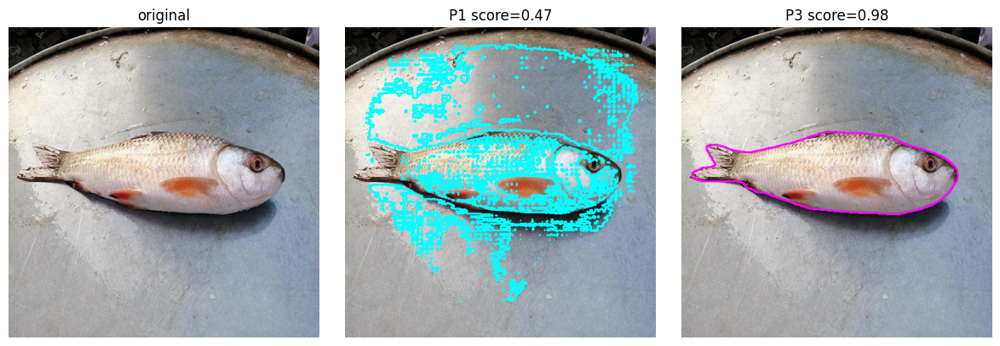

In [9]:
fp_t = muestra['filepath'].iloc[0]  # primera imagen de la muestra
img_t = leer_rgb(fp_t)
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(img_t); axs[0].set_title('original')
for ax, p, col in zip(axs[1:], ('P1', 'P3'), ((0, 255, 255), (255, 0, 255))):
    m, sc, n, resp, seg = segmentar_fila(fp_t, p)
    assert m.shape == (500, 500) and m.dtype == np.uint8 and set(np.unique(m)) <= {0, 255}, 'salida inválida'  # comprobación de contrato
    print(p, '| forma', m.shape, '| dtype', m.dtype, '| valores', np.unique(m), f'| score {sc:.3f} | candidatas {n} | respaldo {resp} | área {np.mean(m > 0):.3f} | {seg:.2f} s')
    ax.imshow(contorno_sobre(img_t, m, col)); ax.set_title(f'{p} score={sc:.2f}')
for ax in axs:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Piloto visual (30 imágenes de val, prompts P1 y P3)

Ahora vamos a leer la máscara de GrabCut desde `masks.zip`. No asumimos carpetas internas: emparejamos por el **stem** (nombre sin extensión, por ejemplo `boal_001`), que es único, y reportamos qué convención usa el zip.

In [10]:
zgc = zipfile.ZipFile(P_MASKS_GC)  # máscaras GrabCut
nombres = [n for n in zgc.namelist() if not n.endswith('/')]
GC_INDEX = {}
for n in nombres:
    s = stem_de(n)
    assert s not in GC_INDEX, f'stem repetido en masks.zip: {s}'
    GC_INDEX[s] = n  # stem -> nombre interno
print('Entradas en masks.zip:', len(nombres), '| ejemplos:', nombres[:3])
print('Extensiones:', sorted({os.path.splitext(n)[1].lower() for n in nombres}), '| carpetas de primer nivel:', sorted({n.split('/')[0] for n in nombres if '/' in n})[:12])
faltan_gc = sorted(set(splits['stem']) - set(GC_INDEX))
print('Imágenes sin máscara GrabCut en el zip:', len(faltan_gc), faltan_gc[:5])
coinciden = sum(GC_INDEX[s] == f'{c}/{s}.png' for s, c in zip(splits['stem'], splits['carpeta']) if s in GC_INDEX)
print(f'Entradas con la convención <clase>/<stem>.png: {coinciden} de {len(GC_INDEX)}',
      '(igual al contrato propio)' if coinciden == len(GC_INDEX) else '(DISTINTA: el cruce se hace por stem; el contrato de masks_sam2.zip sigue siendo <clase>/<stem>.png)')

def leer_gc(stem):  # máscara GrabCut {0,255} por stem
    buf = np.frombuffer(zgc.read(GC_INDEX[stem]), np.uint8)
    m = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
    assert m is not None and m.shape == (500, 500), f'máscara GrabCut inválida: {stem}'
    return ((m > 127) * 255).astype(np.uint8)

Entradas en masks.zip: 8975 | ejemplos: ['boal/boal_292.png', 'boal/boal_283.png', 'boal/boal_123.png']
Extensiones: ['.png'] | carpetas de primer nivel: ['boal', 'ilish', 'kalibaush', 'katla', 'koi', 'mrigel', 'pabda', 'rui', 'telapia']
Imágenes sin máscara GrabCut en el zip: 0 []
Entradas con la convención <clase>/<stem>.png: 8975 de 8975 (igual al contrato propio)


Ahora vamos a correr el piloto: los dos prompts sobre las 30 imágenes, guardando cada PNG en `sam2/piloto/<P1|P3>/<stem>.png`. Cronometramos solo el modelo (`set_image` más `predict`), **excluyendo el primer calentamiento**, y estimamos el lote completo:
$$T_{\text{lote}} \approx \frac{8975\,\bar{t}}{60}\ \text{minutos}.$$
El paso es idempotente: si el CSV de resultados y los 60 PNG ya existen y son consistentes, se cargan.

In [11]:
RUTA_PIL_RES = f'{SAM2_DIR}/piloto/piloto_resultados.csv'  # resultados del piloto (reanudable)

def piloto_cargable():  # devuelve la tabla si es consistente con la muestra actual y los PNG existen
    if not os.path.exists(RUTA_PIL_RES):
        return None
    d = pd.read_csv(RUTA_PIL_RES)
    esperado = {(fp, p) for fp in muestra['filepath'] for p in ('P1', 'P3')}
    if {(a, b) for a, b in zip(d['filepath'], d['prompt'])} != esperado or d['score'].isna().any():
        return None
    if not all(os.path.exists(f'{SAM2_DIR}/piloto/{p}/{stem_de(fp)}.png') for fp, p in esperado):
        return None
    return d

piloto_res = piloto_cargable()
if piloto_res is None:
    print('Calculando el piloto...')
    _ = segmentar_fila(muestra['filepath'].iloc[0], 'P1')  # calentamiento (no se cuenta en los tiempos)
    filas = []
    for p in ('P1', 'P3'):
        for r in tqdm(list(muestra.itertuples(index=False)), desc=f'piloto {p}'):
            m, sc, n, resp, seg = segmentar_fila(r.filepath, p)
            guardar_png_atomico(f'{SAM2_DIR}/piloto/{p}/{r.stem}.png', m)
            filas.append({'filepath': r.filepath, 'prompt': p, 'score': sc, 'n_cand': n, 'uso_respaldo': resp, 'segundos': seg})
    piloto_res = pd.DataFrame(filas)
    guardar_csv_atomico(piloto_res, RUTA_PIL_RES)
else:
    print('Piloto ya calculado: se carga desde', RUTA_PIL_RES)
piloto_res = piloto_res[['filepath', 'prompt', 'score', 'n_cand', 'uso_respaldo', 'segundos']].merge(muestra[['filepath', 'id', 'estrato']], on='filepath', how='left')
assert piloto_res['id'].notna().all()

t_medio = piloto_res.groupby('prompt')['segundos'].mean()  # segundos por imagen, sin calentamiento
N_TOTAL = len(splits)
for p in ('P1', 'P3'):
    print(f'{p}: {t_medio[p]:.3f} s/imagen -> lote completo de {N_TOTAL} imágenes ~ {N_TOTAL * t_medio[p] / 60:.1f} min (solo modelo)')
print(f'\nESTIMACIÓN DEL LOTE con PROMPT={PROMPT}: ~ {N_TOTAL * t_medio[PROMPT] / 60:.1f} minutos (sin contar lectura/escritura en Drive).')

Calculando el piloto...


piloto P1:   0%|          | 0/30 [00:00<?, ?it/s]

piloto P3:   0%|          | 0/30 [00:00<?, ?it/s]

P1: 0.188 s/imagen -> lote completo de 8975 imágenes ~ 28.2 min (solo modelo)
P3: 0.207 s/imagen -> lote completo de 8975 imágenes ~ 31.0 min (solo modelo)

ESTIMACIÓN DEL LOTE con PROMPT=P3: ~ 31.0 minutos (sin contar lectura/escritura en Drive).


Ahora vamos a mostrar las cuadrículas del piloto, una por estrato y en páginas de 5 filas. Columnas: original, GrabCut (contorno amarillo), P1 (contorno cian) y P3 (contorno magenta), siempre sobre la imagen original. El título lleva el **id**, el estrato y el score. Míralas y anota en qué ids cada prompt acierta el pez (`bien`), lo acierta a medias (`parcial`) o falla (`mal`).

--- estrato aleatoria, página 1 ---


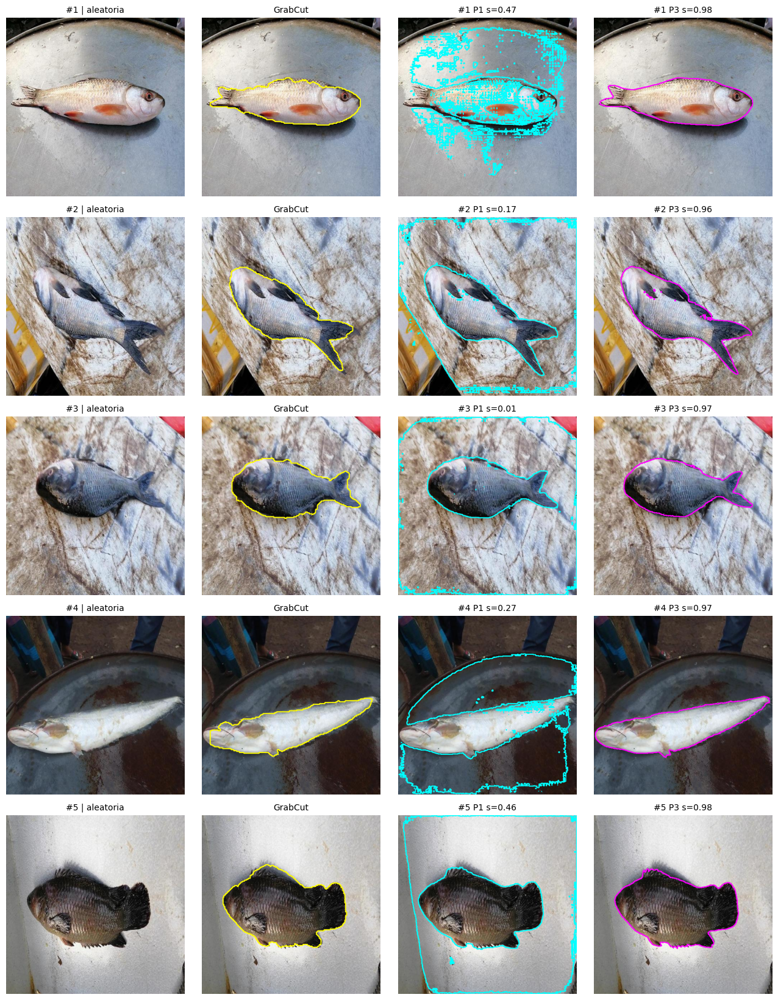

--- estrato aleatoria, página 2 ---


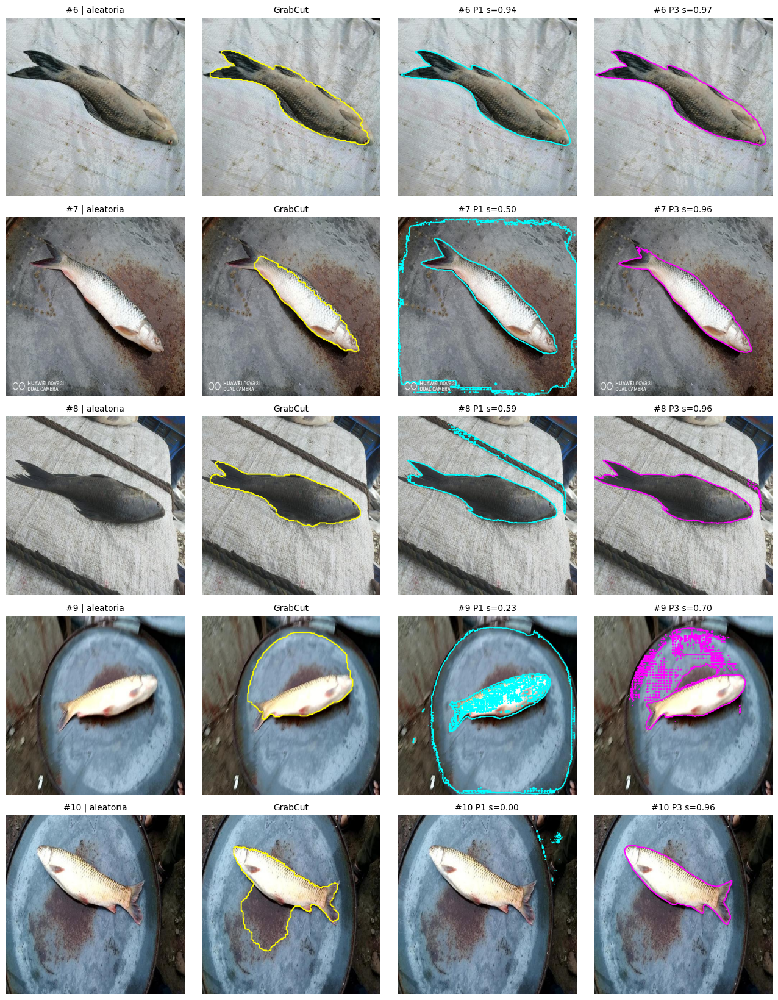

--- estrato aleatoria, página 3 ---


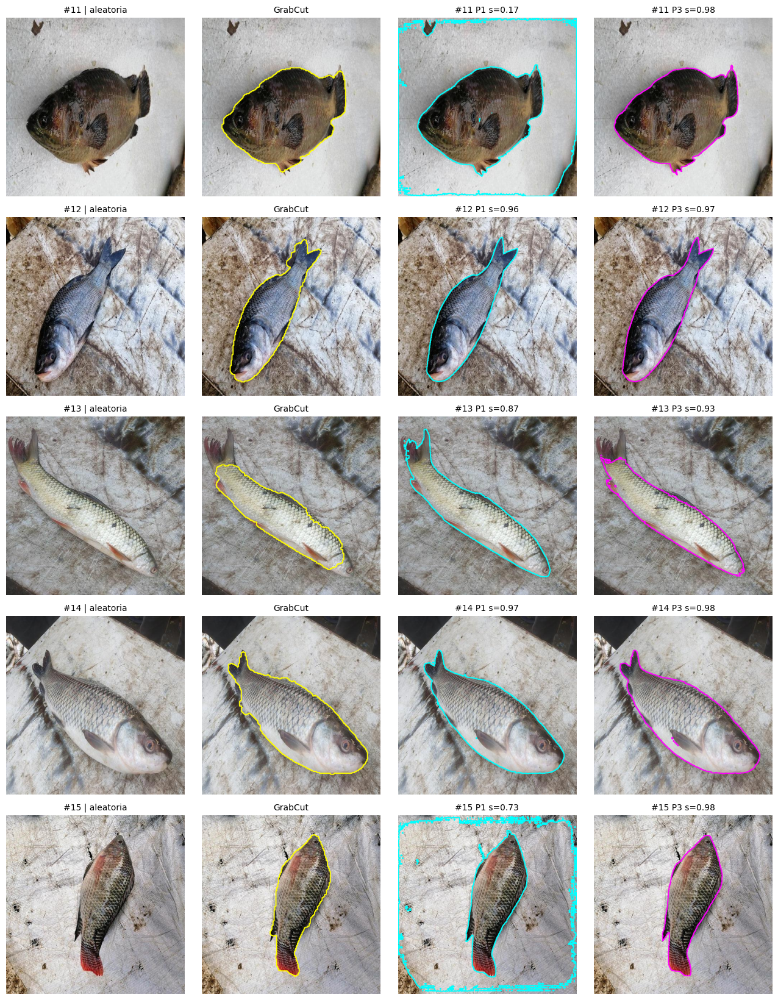

--- estrato peor, página 1 ---


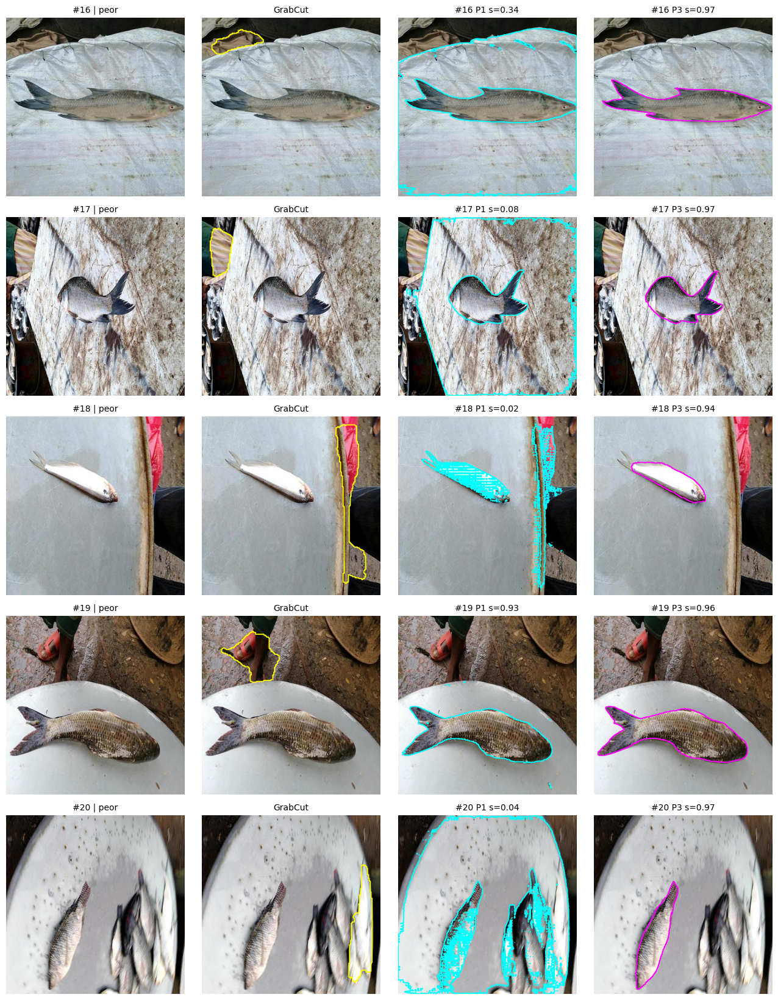

--- estrato peor, página 2 ---


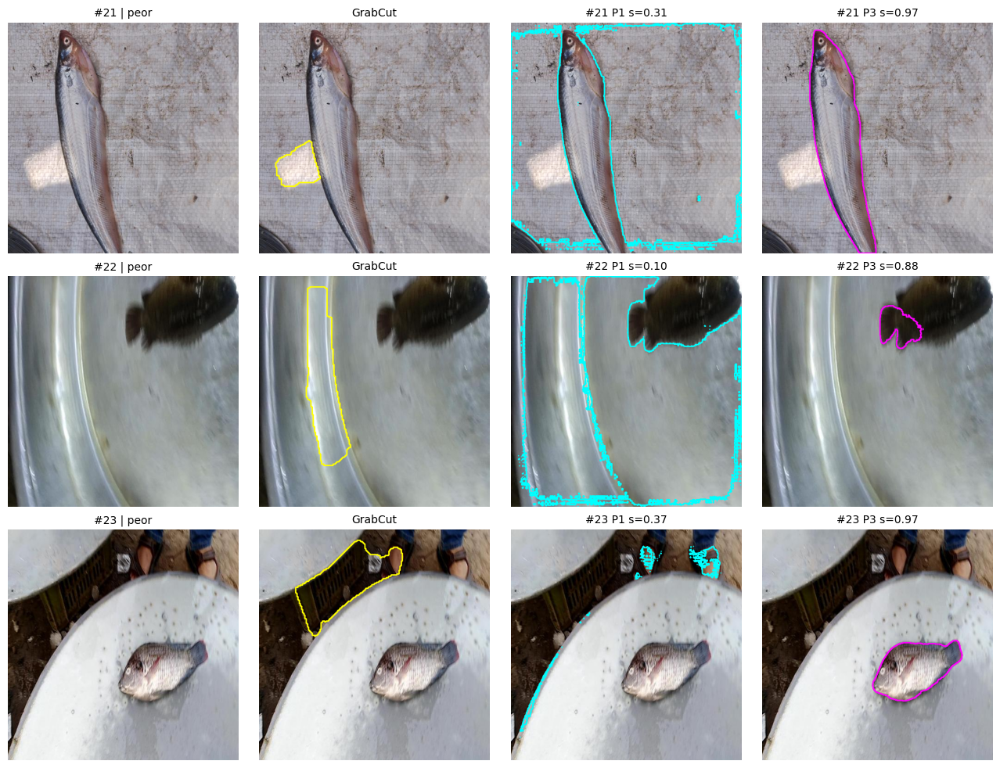

--- estrato descartada, página 1 ---


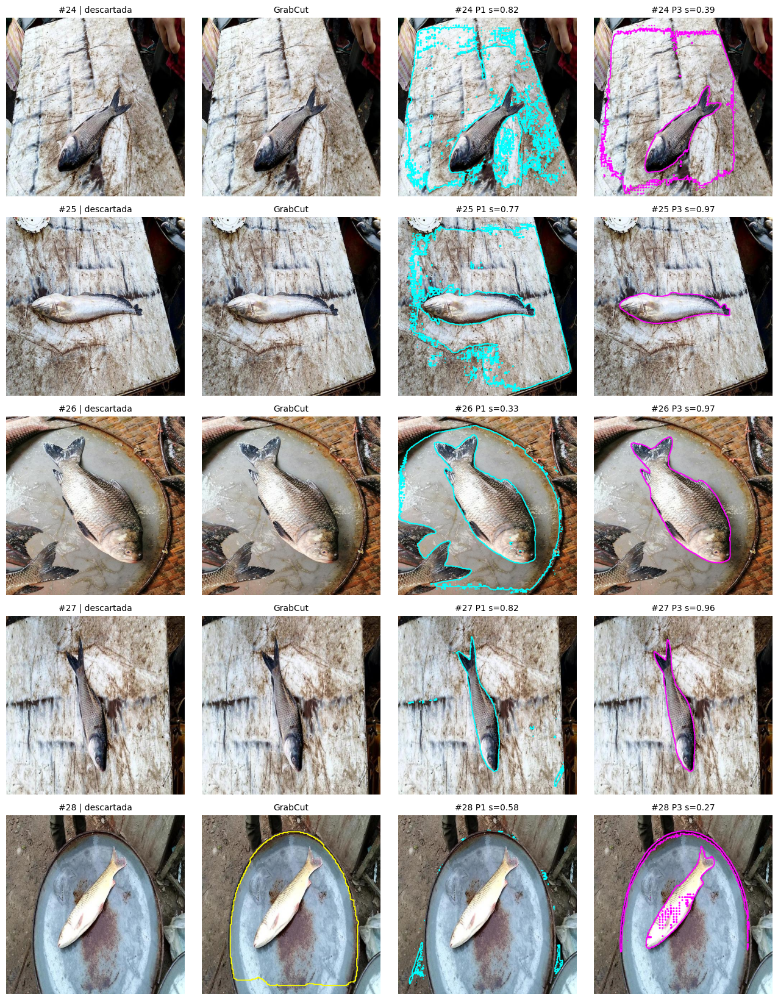

--- estrato descartada, página 2 ---


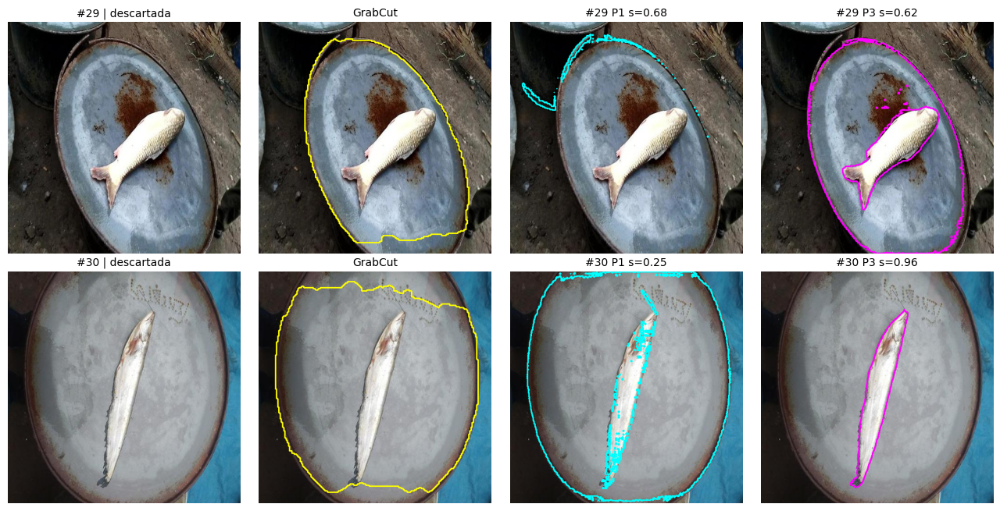

In [12]:
COL = {'GC': (255, 255, 0), 'P1': (0, 255, 255), 'P3': (255, 0, 255)}  # colores RGB de los contornos
SC_DIC = {(r.filepath, r.prompt): r.score for r in piloto_res.itertuples(index=False)}  # score por (filepath, prompt)
RS_DIC = {(r.filepath, r.prompt): r.uso_respaldo for r in piloto_res.itertuples(index=False)}  # respaldo por (filepath, prompt)

def cuadricula_piloto(sub, archivo):  # una página de filas: original | GrabCut | P1 | P3
    fig, axs = plt.subplots(len(sub), 4, figsize=(13, 3.3 * len(sub)), squeeze=False)
    for i, r in enumerate(sub.itertuples(index=False)):
        img = leer_rgb(r.filepath)
        mp = {p: leer_png_gris(f'{SAM2_DIR}/piloto/{p}/{r.stem}.png') for p in ('P1', 'P3')}
        vistas = [(img, f'#{r.id} | {r.estrato}'),
                  (contorno_sobre(img, leer_gc(r.stem), COL['GC']), 'GrabCut'),
                  (contorno_sobre(img, mp['P1'], COL['P1']), f"#{r.id} P1 s={SC_DIC[(r.filepath, 'P1')]:.2f}"),
                  (contorno_sobre(img, mp['P3'], COL['P3']), f"#{r.id} P3 s={SC_DIC[(r.filepath, 'P3')]:.2f}" + (' (resp.)' if RS_DIC[(r.filepath, 'P3')] else ''))]
        for j, (im, tit) in enumerate(vistas):
            axs[i, j].imshow(im); axs[i, j].set_title(tit, fontsize=10); axs[i, j].axis('off')
    plt.tight_layout()
    plt.savefig(f'{FIG}/{archivo}', dpi=90)
    plt.show(); plt.close(fig)

for est in ('aleatoria', 'peor', 'descartada'):
    sub_est = muestra[muestra['estrato'] == est]
    for pag, ini in enumerate(range(0, len(sub_est), 5), 1):
        print(f'--- estrato {est}, página {pag} ---')
        cuadricula_piloto(sub_est.iloc[ini:ini + 5], f'sam2_piloto_{est}_p{pag}.png')

Ahora vamos a registrar tus calificaciones. Pega en `CALIF` las listas de ids (1 a 30) por prompt: cada id debe aparecer en **exactamente una** lista por prompt. La celda valida, calcula $b$ = número de `bien` sobre 30 por prompt, imprime los conteos por estrato (solo informativos, no son compuerta), guarda `sam2_piloto.csv` y aplica el criterio:

- **Bien**: $b \geq 24$ (seguir al lote con ese prompt).
- **Regular**: $18 \leq b \leq 23$ (árbol de acciones, una sola ronda de ajustes).
- **Mal**: $b < 18$ (descartar primero errores mecánicos; si no, parar).

Si ambos prompts empatan, se prefiere P1 (independiente de la U-Net v1). Si ya calificaste antes y `CALIF` está vacío, se cargan las calificaciones guardadas.

In [14]:
CALIF = {  # pega aquí tus listas de ids (1..30); ejemplo: 'bien': [1, 2, 5, ...]
    'P1': {'bien': [], 'parcial': [], 'mal': [], 'sin_calificar': list(range(1, 31))},  # P1 no se calificó imagen por imagen
    'P3': {'bien': [i for i in range(1, 31) if i not in (22, 28, 29)], 'parcial': [], 'mal': [22, 28, 29], 'sin_calificar': []},
}
RUTA_PILOTO = f'{TAB}/sam2_piloto.csv'  # salida con contrato fijo

def validar_calif(calif):  # cada id 1..30 en exactamente una lista por prompt; devuelve {(prompt, id): juicio}
    juicio = {}
    for p in ('P1', 'P3'):
        asign = {}
        for j in ('bien', 'parcial', 'mal', 'sin_calificar'):
            for i in calif[p].get(j, []):
                asign.setdefault(i, []).append(j)
        faltan = sorted(set(range(1, 31)) - set(asign))
        dup = sorted(i for i, v in asign.items() if len(v) > 1)
        fuera = sorted(i for i in asign if i not in range(1, 31))
        assert not (faltan or dup or fuera), f'{p}: faltan {faltan} | repetidos {dup} | fuera de 1..30 {fuera}'
        for i, v in asign.items():
            juicio[(p, i)] = v[0]
    return juicio

calif_vacia = all(len(v) == 0 for p in CALIF.values() for v in p.values())
if calif_vacia and os.path.exists(RUTA_PILOTO) and pd.read_csv(RUTA_PILOTO)['juicio'].notna().all():
    print('CALIF vacío: se cargan las calificaciones ya guardadas en', RUTA_PILOTO)
    tabla_piloto = pd.read_csv(RUTA_PILOTO)
else:
    juicio = validar_calif(CALIF)  # falla con mensaje claro si algo no cuadra
    tabla_piloto = piloto_res[['filepath', 'estrato', 'id', 'prompt', 'score', 'uso_respaldo']].copy()
    tabla_piloto['juicio'] = [juicio[(p, i)] for p, i in zip(tabla_piloto['prompt'], tabla_piloto['id'])]
    tabla_piloto = tabla_piloto[['filepath', 'estrato', 'id', 'prompt', 'score', 'juicio', 'uso_respaldo']].sort_values(['prompt', 'id'])
    guardar_csv_atomico(tabla_piloto, RUTA_PILOTO)
    print('Guardado:', RUTA_PILOTO)

b_piloto = {p: int((tabla_piloto[tabla_piloto['prompt'] == p]['juicio'] == 'bien').sum()) for p in ('P1', 'P3')}  # b sobre 30
cuentas = pd.crosstab([tabla_piloto['prompt'], tabla_piloto['estrato']], tabla_piloto['juicio']).reindex(columns=['bien', 'parcial', 'mal'], fill_value=0)
print('\nConteos por estrato (informativos; aleatoria 15, peor 8, descartada 7):')
print(cuentas)

def veredicto(b):  # criterio escrito
    return 'Bien' if b >= 24 else ('Regular' if b >= 18 else 'Mal')

P1_SIN_CALIFICAR = bool((tabla_piloto[tabla_piloto['prompt'] == 'P1']['juicio'] == 'sin_calificar').all())
for p in ('P1', 'P3'):
    if p == 'P1' and P1_SIN_CALIFICAR:
        print('P1: sin calificar imagen por imagen (comparación informal)')
    else:
        print(f'{p}: b = {b_piloto[p]} / 30 -> {veredicto(b_piloto[p])}')
cand = {p: b for p, b in b_piloto.items() if not (p == 'P1' and P1_SIN_CALIFICAR)}
mejor_b = max(cand.values())
empatan = [p for p in cand if cand[p] == mejor_b]
recomendado = 'P1' if 'P1' in empatan else empatan[0]
if len(empatan) == 2:  # solo si ambos se calificaron
    print('Empate: se prefiere P1 porque es independiente de la U-Net v1.')
print(f'Prompt recomendado: {recomendado}. PROMPT actual en la sección 0: {PROMPT}.')
if PROMPT != recomendado:
    print(f'ATENCIÓN: cambia PROMPT a {recomendado} en la sección 0 antes del lote (o justifica mantener {PROMPT}).')

v = veredicto(b_piloto[recomendado])
if v == 'Bien':
    print('\nBIEN: sigue al lote completo con ese prompt.')
elif v == 'Regular':
    print('\nREGULAR: una sola ronda de ajustes. Árbol de acciones:\n'
          ' 1. Mira dónde falla (escenas con plato o balde).\n'
          ' 2. Prueba P3 por defecto y P1 cuando unet_vacia.\n'
          ' 3. Prueba un punto negativo en una esquina.\n'
          ' 4. Un checkpoint mayor solo si el fallo es de borde.\n'
          ' 5. Vuelve a calificar; si no llegas a 24, decide si sigues (FORZAR_LOTE) con lo que hay.')
else:
    print('\nMAL: primero descarta errores mecánicos:\n'
          ' - BGR vs RGB (cv2.imread es BGR).\n'
          ' - Caja en xywh en vez de xyxy.\n'
          ' - Coordenadas a 256 en vez de 500.\n'
          ' Si no es mecánico, PARA: no sigas al lote.')

Guardado: /content/drive/MyDrive/sylfish/reports/tables/sam2_piloto.csv

Conteos por estrato (informativos; aleatoria 15, peor 8, descartada 7):
juicio             bien  parcial  mal
prompt estrato                       
P1     aleatoria      0        0    0
       descartada     0        0    0
       peor           0        0    0
P3     aleatoria     15        0    0
       descartada     5        0    2
       peor           7        0    1
P1: sin calificar imagen por imagen (comparación informal)
P3: b = 27 / 30 -> Bien
Prompt recomendado: P3. PROMPT actual en la sección 0: P3.

BIEN: sigue al lote completo con ese prompt.


## 4. Lote completo

Ahora vamos a procesar todas las imágenes con `PROMPT`, en el orden de `SPLITS_ORDEN`, por bloques (split, clase). Cada máscara se escribe primero en `/content/sam2_raw/<clase>/<stem>.png` y al terminar cada bloque se copia a `sam2/masks_raw/` saltando lo que ya existe; `scores.csv` se guarda de forma atómica al cerrar cada bloque y un journal local cada 250 imágenes. Si la sesión se corta, se vuelve a ejecutar la celda y continúa. **No se filtra nada aquí.**

Antes de arrancar, la celda comprueba que el piloto autoriza el lote (al menos 18 de 30 `bien` con `PROMPT`, leído desde `sam2_piloto.csv`) y que la configuración no cambió a mitad de un lote.

In [16]:
def leer_b_piloto():  # b por prompt desde el CSV guardado (sobrevive a desconexiones)
    assert os.path.exists(RUTA_PILOTO), 'Falta sam2_piloto.csv: ejecuta la celda de calificaciones de la sección 3'
    d = pd.read_csv(RUTA_PILOTO)
    assert len(d) == 60 and d['juicio'].notna().all(), 'sam2_piloto.csv incompleto'
    return {p: int((g['juicio'] == 'bien').sum()) for p, g in d.groupby('prompt')}

b_gate = leer_b_piloto()
print('b del piloto:', b_gate, '| PROMPT =', PROMPT)
assert FORZAR_LOTE or b_gate[PROMPT] >= 18, f'El piloto de {PROMPT} dio b={b_gate[PROMPT]} < 18: no se corre el lote (FORZAR_LOTE=True para saltar esta guarda)'
if PROMPT == 'P3':
    assert set(splits.loc[splits['split'].isin(SPLITS_ORDEN), 'filepath']) <= set(PROM), 'P3 necesita prompts.csv para todas las imágenes del lote'

verificar_config(f'{SAM2_DIR}/lote_config.json', {'prompt': PROMPT, 'model_cfg': MODEL_CFG, 'checkpoint': CKPT_NAME, 'precision': PRECISION,
                                                  'margen_p1': MARGEN_P1, 'ampliar_p3': AMPLIAR_P3}, 'el lote')

lote = splits[splits['split'].isin(SPLITS_ORDEN)].copy()  # imágenes a procesar
lote['o'] = lote['split'].map({s: i for i, s in enumerate(SPLITS_ORDEN)})
lote = lote.sort_values(['o', 'carpeta'], kind='stable').reset_index(drop=True)  # orden: split, luego clase
print('Imágenes del lote:', len(lote), lote['split'].value_counts().to_dict())

def fn_lote(r):  # segmenta una imagen del lote con PROMPT
    m, sc, n, resp, seg = segmentar_fila(r.filepath, PROMPT)
    return m, {'score': sc, 'n_candidatas': n}

SCORES = procesar_por_bloques(lote, fn_lote, LOCAL_RAW, DRIVE_RAW, f'{LOCAL_RAW}/scores_local.csv', f'{SAM2_DIR}/scores.csv',
                              ['score', 'n_candidatas'], 'lote SAM 2')
assert set(SCORES) == set(lote['filepath']), 'faltan scores de algunas imágenes del lote'
print('Listo. scores.csv en', f'{SAM2_DIR}/scores.csv', '| imágenes con score:', len(SCORES))

b del piloto: {'P1': 0, 'P3': 27} | PROMPT = P3
Imágenes del lote: 8975 {'train': 6246, 'test': 1370, 'val': 1359}
lote SAM 2: total 8975, ya hechas 0, pendientes 8975


lote SAM 2:   0%|          | 0/8975 [00:00<?, ?it/s]

Listo. scores.csv en /content/drive/MyDrive/sylfish/sam2/scores.csv | imágenes con score: 8975


Ahora vamos a verificar el lote: todos los archivos presentes en Drive, todos de $500\times500$ con valores en $\{0, 255\}$, máscaras vacías por clase y split, e histograma del `score`.

verificando:   0%|          | 0/8975 [00:00<?, ?it/s]

OK: 8975 máscaras crudas, todas 500x500 con valores {0,255} (esperadas 8975).

Máscaras vacías por clase y split:
split      test  train  val  All
carpeta                         
boal          0      0    0    0
ilish         0      0    0    0
kalibaush     0      0    0    0
katla         0      0    0    0
koi           0      0    0    0
mrigel        0      0    0    0
pabda         0      0    0    0
rui           0      0    0    0
telapia       0      0    0    0
All           0      0    0    0


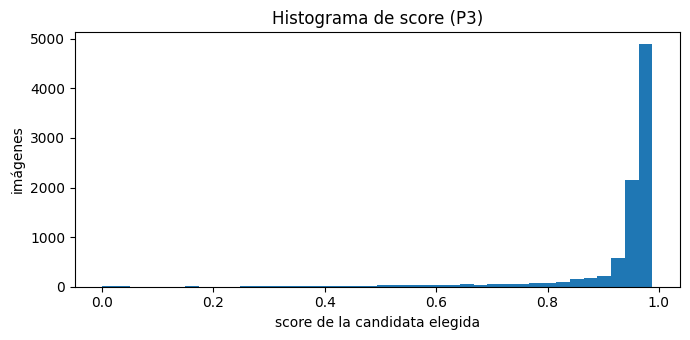

count    8975.000000
mean        0.930022
std         0.108883
min         0.000569
25%         0.945161
50%         0.966147
75%         0.974417
max         0.988532
dtype: float64


In [17]:
def ruta_lectura(tipo, carpeta, stem):  # local si existe; si no, Drive
    loc, dri = BASES[tipo]
    p = f'{loc}/{carpeta}/{stem}.png'
    return p if os.path.exists(p) else f'{dri}/{carpeta}/{stem}.png'

faltan_drive = []  # filepath cuya máscara no está en Drive
for c, g in lote.groupby('carpeta'):  # cada clase: todos los PNG deben estar en Drive
    en_drive = listar_archivos(f'{DRIVE_RAW}/{c}')
    faltan_drive += [r.filepath for r in g.itertuples(index=False) if f'{r.stem}.png' not in en_drive]
assert not faltan_drive, f'{len(faltan_drive)} máscaras no están en Drive, p. ej. {faltan_drive[:3]}'

filas = []
for r in tqdm(list(lote.itertuples(index=False)), desc='verificando'):
    m = cv2.imread(ruta_lectura('raw', r.carpeta, r.stem), cv2.IMREAD_UNCHANGED)
    assert m is not None and m.shape == (500, 500), f'forma inválida en {r.filepath}'
    assert set(np.unique(m)) <= {0, 255}, f'valores fuera de {{0,255}} en {r.filepath}'
    filas.append({'filepath': r.filepath, 'split': r.split, 'carpeta': r.carpeta, 'area_frac': float((m > 0).mean()), 'vacia': bool((m > 0).sum() == 0)})
verif = pd.DataFrame(filas)
print(f'OK: {len(verif)} máscaras crudas, todas 500x500 con valores {{0,255}} (esperadas {len(lote)}).')

vacias = verif.pivot_table(index='carpeta', columns='split', values='vacia', aggfunc='sum', fill_value=0, margins=True)
print('\nMáscaras vacías por clase y split:')
print(vacias)
guardar_csv_atomico(vacias.reset_index(), f'{TAB}/sam2_vacias_crudas.csv')

sc_serie = pd.Series({fp: v['score'] for fp, v in SCORES.items()})
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(sc_serie, bins=40); ax.set_xlabel('score de la candidata elegida'); ax.set_ylabel('imágenes'); ax.set_title(f'Histograma de score ({PROMPT})')
plt.tight_layout(); plt.savefig(f'{FIG}/sam2_hist_score.png', dpi=90); plt.show(); plt.close(fig)
print(sc_serie.describe())

Ahora vamos a mirar una cuadrícula de 24 imágenes al azar (semilla 42) con la máscara cruda superpuesta. Cuenta a ojo en cuántas la máscara sigue al pez.

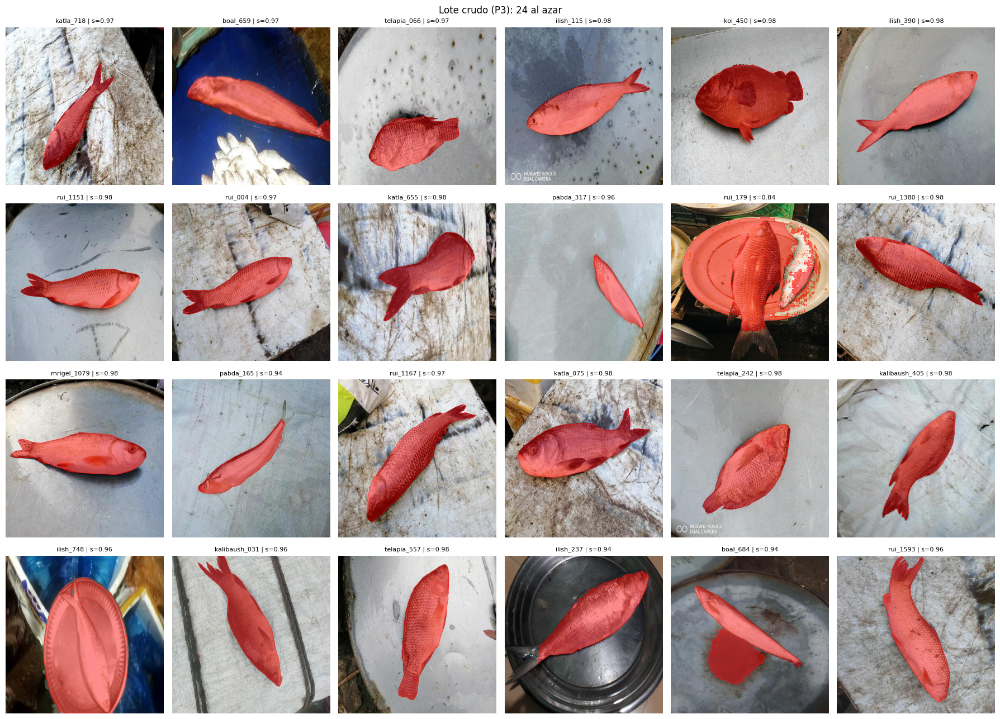

In [18]:
m24 = lote.sample(24, random_state=SEMILLA)  # 24 imágenes al azar
cuadricula_mascaras(m24, 'raw', f'Lote crudo ({PROMPT}): 24 al azar', 'sam2_lote_azar24.png',
                    extra=lambda r: f"{r.stem} | s={SCORES[r.filepath]['score']:.2f}")

Ahora vamos a registrar cuántas de las 24 siguen bien al pez. La lectura del lote, derivada de las proporciones del piloto ($24/30$ y $18/30$), es:

| Resultado a ojo (de 24) | Lectura | Qué hacer |
|---|---|---|
| Bien: 20 a 24 siguen al pez | el lote se parece al piloto | pasar al posproceso |
| Regular: 15 a 19 | falla en escenas con plato o balde | seguir, pero el control de calidad de la sección 6 debe ser estricto |
| Mal: 14 o menos | el lote no se parece al piloto | parar y revisar el cruce |

Si la cuadrícula **no se parece al piloto**, casi siempre es una desalineación entre `filepath` y `prompts.csv`: verifica que el cruce sea por `filepath` y no por posición.

In [19]:
LOTE_BIEN_24 = 20  # número de imágenes (de 24) en las que la máscara sigue al pez a ojo
if LOTE_BIEN_24 is None:
    print('Pendiente: escribe LOTE_BIEN_24 (0 a 24) tras mirar la cuadrícula.')
else:
    assert 0 <= LOTE_BIEN_24 <= 24
    lectura = 'Bien' if LOTE_BIEN_24 >= 20 else ('Regular' if LOTE_BIEN_24 >= 15 else 'Mal')
    print(f'{LOTE_BIEN_24}/24 -> {lectura}')
    if lectura == 'Mal':
        print('PARA: revisa el cruce por filepath con prompts.csv y los errores mecánicos antes de seguir.')

20/24 -> Bien


## 5. Posproceso con OpenCV

Ahora vamos a definir `posprocesar(mask)` con sus parámetros en un diccionario que se guarda en `sam2_mask_params.json`. Pasos: (1) binarizar a $\{0,255\}$; (2) quedarnos con la componente conexa mayor (`cv2.connectedComponentsWithStats`), guardando
$$\text{frac\_cc\_mayor} = \frac{\text{área de la mayor}}{\text{área total}}$$
**antes** de filtrar; (3) rellenar huecos dibujando el contorno externo relleno (`RETR_EXTERNAL` y `drawContours` con $-1$); (4) apertura $k\times k$ solo si `APERTURA_K > 0` (por defecto no, para no borrar aletas finas).

In [20]:
PARAMS_POST = {'binarizar_umbral': 127, 'componente_mayor': True, 'conectividad': 8, 'rellenar_huecos': True, 'apertura_k': APERTURA_K}  # parámetros del posproceso

def posprocesar(mask):  # devuelve (máscara uint8 {0,255}, frac_cc_mayor)
    b = (mask > PARAMS_POST['binarizar_umbral']).astype(np.uint8)  # (1) binarizar
    if b.sum() == 0:
        return np.zeros(mask.shape, np.uint8), 0.0
    n, lab, st, _ = cv2.connectedComponentsWithStats(b, connectivity=PARAMS_POST['conectividad'])  # (2) componentes
    areas = st[1:, cv2.CC_STAT_AREA]
    frac = float(areas.max() / areas.sum())  # fracción de la mayor ANTES de filtrar
    if PARAMS_POST['componente_mayor']:
        b = (lab == 1 + int(np.argmax(areas))).astype(np.uint8)
    if PARAMS_POST['rellenar_huecos']:  # (3) rellenar huecos con el contorno externo
        cs, _ = cv2.findContours(b, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        relleno = np.zeros_like(b)
        cv2.drawContours(relleno, cs, -1, 1, thickness=cv2.FILLED)
        b = relleno
    out = b * 255
    k = PARAMS_POST['apertura_k']
    if k > 0:  # (4) apertura kxk opcional
        out = cv2.morphologyEx(out, cv2.MORPH_OPEN, np.ones((k, k), np.uint8))
    return out.astype(np.uint8), frac

BANDA = np.ones((500, 500), bool)  # banda de BANDA_BORDE px en el borde de la imagen
BANDA[BANDA_BORDE:-BANDA_BORDE, BANDA_BORDE:-BANDA_BORDE] = False

def metricas_mascara(m):  # (area_frac, borde_frac) de una máscara {0,255}
    b = m > 127
    return float(b.sum() / b.size), float(b[BANDA].sum() / BANDA.sum())

guardar_json_atomico({'posproceso': PARAMS_POST, 'qc': None}, f'{SAM2_DIR}/sam2_mask_params.json')  # versión inicial; se completa en la sección 6
print('Parámetros del posproceso:', PARAMS_POST, '| banda de borde:', int(BANDA.sum()), 'px')

Parámetros del posproceso: {'binarizar_umbral': 127, 'componente_mayor': True, 'conectividad': 8, 'rellenar_huecos': True, 'apertura_k': 0} | banda de borde: 9900 px


Ahora vamos a probar `posprocesar` en la imagen de la muestra con más componentes o huecos (si hay), mirando antes y después. Es una comprobación visual rápida.

mrigel_277: componentes 279 -> 1 | frac_cc_mayor 0.714 | área 0.135 -> 0.098


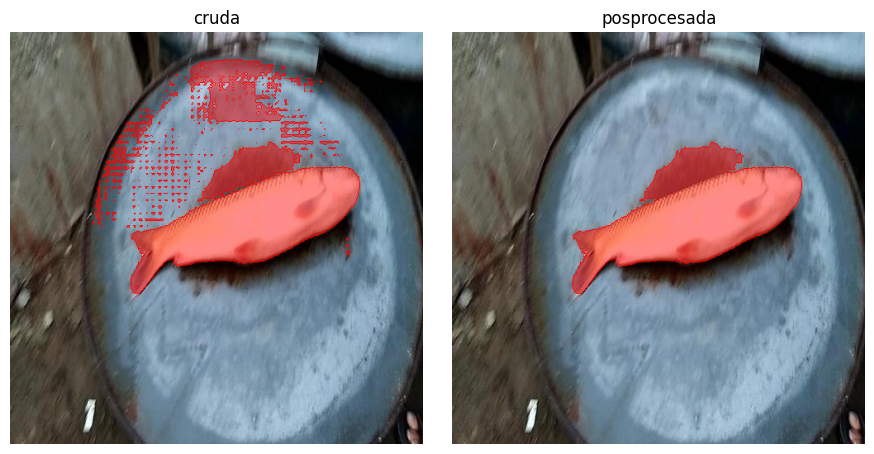

In [23]:
def n_comp(m):  # número de componentes conexas de una máscara
    return cv2.connectedComponents((m > 127).astype(np.uint8), connectivity=8)[0] - 1

cand = muestra.assign(nc=[n_comp(leer_mascara('raw', r.carpeta, r.stem)) for r in muestra.itertuples(index=False)])
r0 = cand.sort_values('nc', ascending=False, kind='stable').iloc[0]  # la imagen con más componentes
raw0 = leer_mascara('raw', r0.carpeta, r0.stem)
fin0, frac0 = posprocesar(raw0)
assert fin0.shape == (500, 500) and fin0.dtype == np.uint8 and set(np.unique(fin0)) <= {0, 255}
print(f'{r0.stem}: componentes {r0.nc} -> {n_comp(fin0)} | frac_cc_mayor {frac0:.3f} | área {np.mean(raw0 > 0):.3f} -> {np.mean(fin0 > 0):.3f}')
img0 = leer_rgb(r0.filepath)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
axs[0].imshow(superponer(img0, raw0)); axs[0].set_title('cruda'); axs[1].imshow(superponer(img0, fin0)); axs[1].set_title('posprocesada')
for ax in axs:
    ax.axis('off')
plt.tight_layout(); plt.show()

Ahora vamos a posprocesar todo el lote y escribir `masks_sam2/<clase>/<stem>.png` (local primero, luego Drive por bloques, idempotente). En paralelo se guardan `frac_cc_mayor`, `area_frac` y `borde_frac` de cada máscara final en `sam2/posproceso_stats.csv`, con
$$\text{area\_frac} = \frac{|M|}{250000},\qquad \text{borde\_frac} = \frac{|M \cap B|}{|B|},$$
donde $B$ es la banda de 5 px en el borde de la imagen. Si cambias los parámetros después de haber posprocesado, la celda se detiene y te pide `REHACER_POSPROCESO = True`.

In [22]:
verificar_config(f'{SAM2_DIR}/posproceso_config.json', PARAMS_POST, 'el posproceso', sobrescribir=REHACER_POSPROCESO)

def fn_pp(r):  # posprocesa una máscara cruda y mide sus estadísticas
    out, frac = posprocesar(leer_mascara('raw', r.carpeta, r.stem))
    a, b = metricas_mascara(out)
    return out, {'frac_cc_mayor': frac, 'area_frac': a, 'borde_frac': b}

COLS_PP = ['frac_cc_mayor', 'area_frac', 'borde_frac']
STATS = procesar_por_bloques(lote, fn_pp, LOCAL_FINAL, DRIVE_FINAL, f'{LOCAL_FINAL}/stats_local.csv', f'{SAM2_DIR}/posproceso_stats.csv',
                             COLS_PP, 'posproceso', forzar=REHACER_POSPROCESO)
assert set(STATS) == set(lote['filepath']), 'faltan estadísticas de posproceso'
for c, g in lote.groupby('carpeta'):  # todas las finales deben estar en Drive
    en_drive = listar_archivos(f'{DRIVE_FINAL}/{c}')
    assert all(f'{s}.png' in en_drive for s in g['stem']), f'faltan máscaras finales de {c} en Drive'
muest_chk = lote.sample(min(200, len(lote)), random_state=SEMILLA)  # chequeo de formato en una muestra
for r in muest_chk.itertuples(index=False):
    m = leer_mascara('final', r.carpeta, r.stem)
    assert m.shape == (500, 500) and set(np.unique(m)) <= {0, 255}, f'máscara final inválida: {r.filepath}'
print('Posproceso completo:', len(STATS), 'máscaras finales; formato verificado en', len(muest_chk), 'al azar.')

posproceso: total 8975, ya hechas 0, pendientes 8975


posproceso:   0%|          | 0/8975 [00:00<?, ?it/s]

Posproceso completo: 8975 máscaras finales; formato verificado en 200 al azar.


## 6. Control de calidad recalibrado (solo val para decidir)

Ahora vamos a armar la tabla por imagen con `score`, `area_frac`, `borde_frac` (fracción ocupada de la banda de 5 px del borde: un pez rara vez la llena, una mesa sí) y `frac_cc_mayor`. **Los umbrales se deciden solo con val**; train y test reciben el mismo criterio sin mirarlos para calibrar.

In [24]:
qc = lote[['filepath', 'split', 'carpeta', 'stem']].copy()  # una fila por imagen procesada, cruzando por filepath
qc['score'] = qc['filepath'].map(lambda f: float(SCORES[f]['score']))
for c in COLS_PP:
    qc[c] = qc['filepath'].map(lambda f, c=c: float(STATS[f][c]))
qv = qc[qc['split'] == 'val']  # solo val para decidir
assert len(qv) > 0, 'val no está procesado: pon "val" en SPLITS_ORDEN'
print(qc.groupby('split')[['score', 'area_frac', 'borde_frac']].describe().T.round(3))

split                 test     train       val
score      count  1370.000  6246.000  1359.000
           mean      0.934     0.929     0.929
           std       0.098     0.110     0.113
           min       0.001     0.002     0.032
           25%       0.947     0.945     0.946
           50%       0.966     0.966     0.965
           75%       0.975     0.974     0.974
           max       0.985     0.987     0.989
area_frac  count  1370.000  6246.000  1359.000
           mean      0.147     0.150     0.147
           std       0.070     0.075     0.077
           min       0.004     0.000     0.001
           25%       0.102     0.103     0.099
           50%       0.140     0.140     0.132
           75%       0.183     0.179     0.175
           max       0.540     0.655     0.659
borde_frac count  1370.000  6246.000  1359.000
           mean      0.003     0.003     0.003
           std       0.013     0.017     0.016
           min       0.000     0.000     0.000
           25

Ahora vamos a ver los histogramas de `area_frac` y `borde_frac` en val.

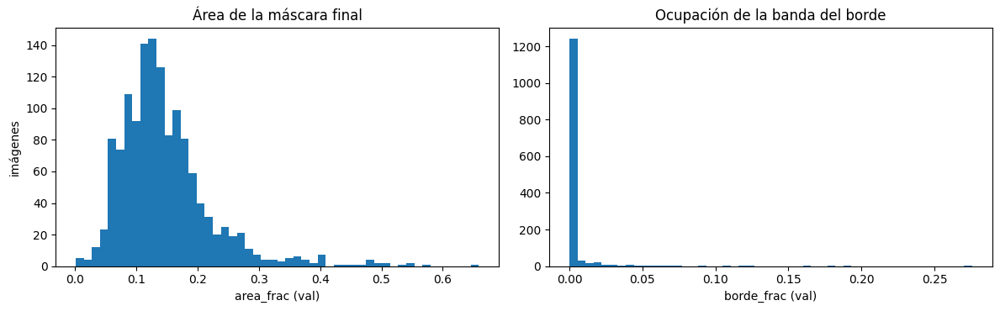

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].hist(qv['area_frac'], bins=50); axs[0].set_xlabel('area_frac (val)'); axs[0].set_ylabel('imágenes'); axs[0].set_title('Área de la máscara final')
axs[1].hist(qv['borde_frac'], bins=50); axs[1].set_xlabel('borde_frac (val)'); axs[1].set_title('Ocupación de la banda del borde')
plt.tight_layout(); plt.savefig(f'{FIG}/sam2_hist_area_borde_val.png', dpi=90); plt.show(); plt.close(fig)

Ahora vamos a mirar 12 imágenes de val por rango de área, con la máscara SAM 2 final superpuesta. **Cuenta a ojo cuántas de las 12 siguen la silueta del pez** en cada rango y de ahí decide `AREA_MIN` y `AREA_MAX`. Cada título trae el stem, el área (`a`), el borde (`b`) y el score (`s`). El primer rango excluye las vacías (área exactamente 0), que se ven aparte.

Rango [0.0, 0.02): 6 imágenes de val


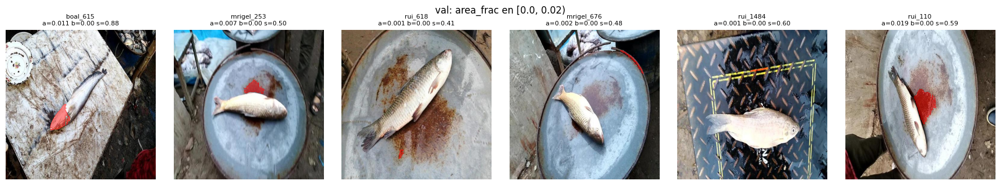

Rango [0.02, 0.15): 838 imágenes de val


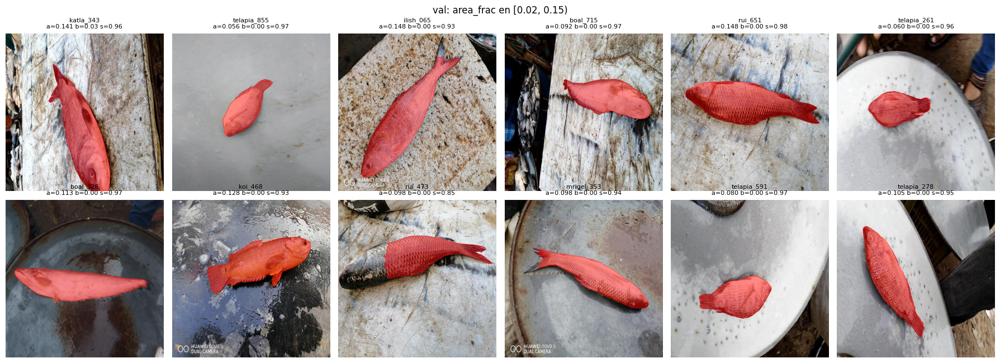

Rango [0.15, 0.3): 462 imágenes de val


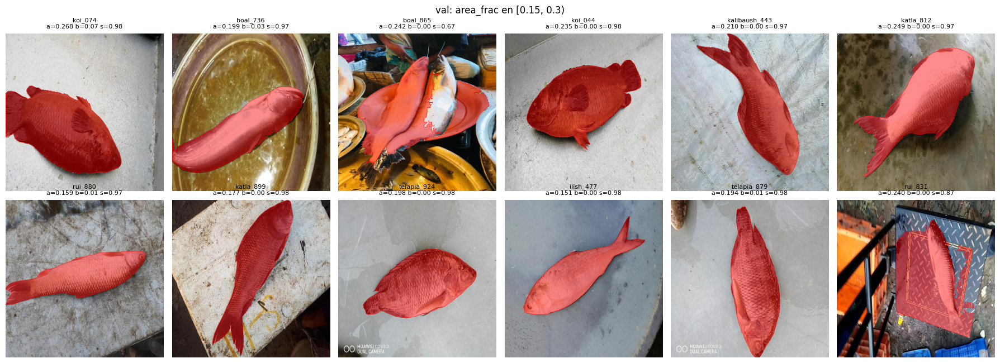

Rango [0.3, 0.45): 38 imágenes de val


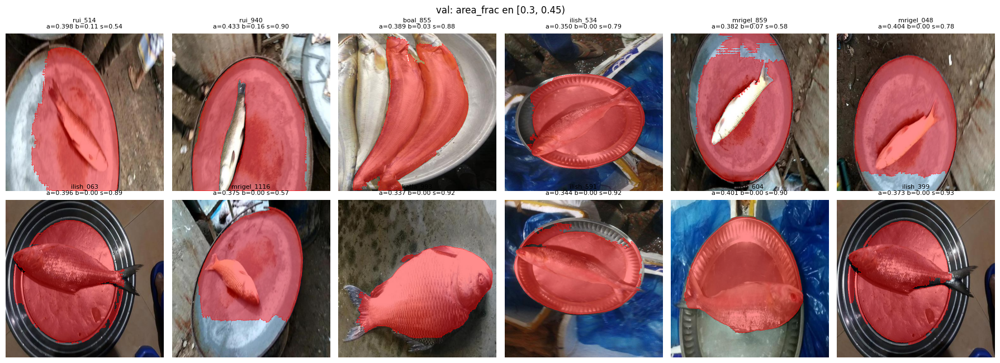

Rango [0.45, 1.0): 15 imágenes de val


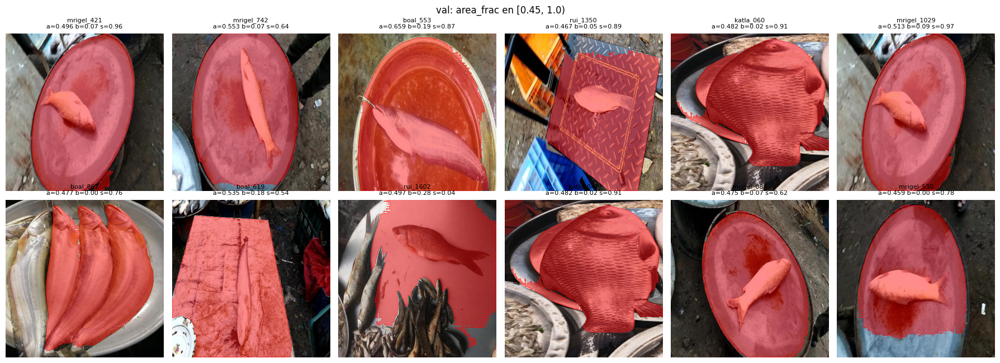

In [26]:
RANGOS = [(0.0, 0.02), (0.02, 0.15), (0.15, 0.30), (0.30, 0.45), (0.45, 1.0001)]  # rangos de area_frac, [a, b)
tit_qc = lambda r: f'{r.stem}\na={r.area_frac:.3f} b={r.borde_frac:.2f} s={r.score:.2f}'
for k, (lo, hi) in enumerate(RANGOS, 1):
    sel = qv[(qv['area_frac'] >= lo) & (qv['area_frac'] < hi) & (qv['area_frac'] > 0)]
    print(f'Rango [{lo}, {min(hi, 1.0)}): {len(sel)} imágenes de val')
    cuadricula_mascaras(sel.sample(min(12, len(sel)), random_state=SEMILLA), 'final', f'val: area_frac en [{lo}, {min(hi, 1.0)})',
                        f'sam2_qc_rango{k}.png', extra=tit_qc)

Ahora vamos a ver las máscaras vacías y las de `borde_frac` más alto en val (las 12 mayores). Sirven para fijar `BORDE_MAX`: mira desde qué valor el borde lleno ya es una mesa o un plato y no un pez.

Vacías en val: 0 de 1359
val: máscaras vacías: no hay imágenes para mostrar


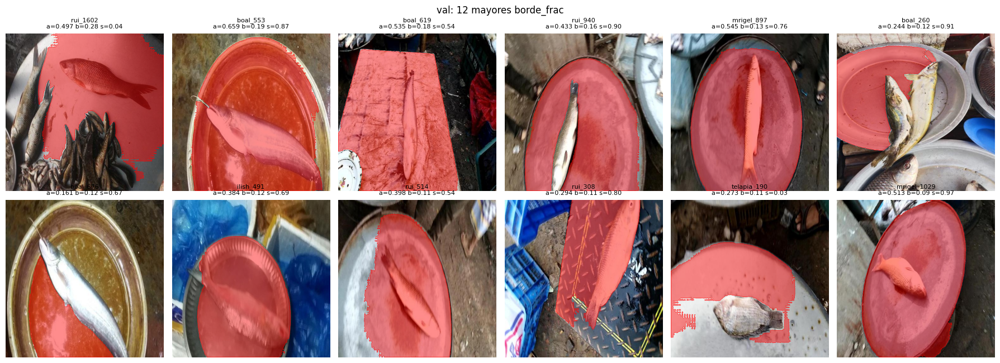

In [27]:
vac = qv[qv['area_frac'] == 0]
print('Vacías en val:', len(vac), 'de', len(qv))
cuadricula_mascaras(vac.sample(min(12, len(vac)), random_state=SEMILLA), 'final', 'val: máscaras vacías', 'sam2_qc_vacias.png', extra=tit_qc)
alto = qv.sort_values('borde_frac', ascending=False, kind='stable').head(12)
cuadricula_mascaras(alto, 'final', 'val: 12 mayores borde_frac', 'sam2_qc_borde_alto.png', extra=tit_qc)

Ahora vamos a asignar `sam2_qc_ok`. **Antes**, edita en la sección 0 las constantes `AREA_MIN`, `AREA_MAX` y `BORDE_MAX` (y vuelve a ejecutar esa celda); si siguen en `None` esta celda se detiene con un mensaje. El `motivo` se asigna en este orden: `vacia`, `area_chica` ($a < $ `AREA_MIN`), `area_grande` ($a > $ `AREA_MAX`), `borde_lleno` ($b >$ `BORDE_MAX`), y `fragmentada` solo si fijaste `FRAC_CC_MIN`; si ninguno aplica, `ok`. Se guardan `sam2_mask_qc.csv` y `sam2_mask_params.json`.

In [29]:
sin_fijar = [n for n, v in (('AREA_MIN', AREA_MIN), ('AREA_MAX', AREA_MAX), ('BORDE_MAX', BORDE_MAX)) if v is None]
assert not sin_fijar, f'Fija {sin_fijar} en la sección 0 (después de ver las cuadrículas de val) y vuelve a ejecutar esa celda.'
assert 0 <= AREA_MIN < AREA_MAX <= 1 and 0 < BORDE_MAX <= 1, 'umbrales fuera de rango'

conds = [qc['area_frac'] == 0, qc['area_frac'] < AREA_MIN, qc['area_frac'] > AREA_MAX, qc['borde_frac'] > BORDE_MAX]
nombres_m = ['vacia', 'area_chica', 'area_grande', 'borde_lleno']
if FRAC_CC_MIN is not None:  # criterio opcional
    conds.append(qc['frac_cc_mayor'] < FRAC_CC_MIN)
    nombres_m.append('fragmentada')
qc['motivo'] = np.select(conds, nombres_m, default='ok')  # el primer criterio que se cumpla
qc['sam2_qc_ok'] = qc['motivo'] == 'ok'

cols_qc = ['filepath', 'score', 'area_frac', 'borde_frac', 'frac_cc_mayor', 'motivo', 'sam2_qc_ok']
guardar_csv_atomico(qc[cols_qc], f'{SAM2_DIR}/sam2_mask_qc.csv')
PARAMS = {'semilla': SEMILLA, 'prompt': PROMPT, 'checkpoint': CKPT_NAME, 'model_cfg': MODEL_CFG, 'precision': PRECISION,
          'splits_procesados': SPLITS_ORDEN, 'posproceso': PARAMS_POST,
          'qc': {'area_min': AREA_MIN, 'area_max': AREA_MAX, 'borde_max': BORDE_MAX, 'frac_cc_min': FRAC_CC_MIN,
                 'banda_borde_px': BANDA_BORDE, 'calibrado_con': 'val'}}
guardar_json_atomico(PARAMS, f'{SAM2_DIR}/sam2_mask_params.json')
print(qc['motivo'].value_counts())
print('Guardados: sam2_mask_qc.csv y sam2_mask_params.json')

motivo
ok             8702
area_grande     204
area_chica       46
borde_lleno      23
Name: count, dtype: int64
Guardados: sam2_mask_qc.csv y sam2_mask_params.json


Ahora vamos a reportar la **retención** (fracción con control de calidad aprobado) de SAM 2 frente a GrabCut sobre las mismas imágenes, calculada desde `mask_qc.csv` y cruzando por `filepath`. Referencia de GrabCut en todo el dataset: 7118 de 8975 aprobadas (boal 63.3 %, ilish 62.6 %, koi 95.7 %, pabda 95.2 %).

**Advertencia:** si la retención sube mucho pero a ojo entran soportes (plato, balde), hay que **endurecer** el control de calidad: entrenar con soportes enseña a segmentar el soporte.

In [30]:
qc_gc = pd.read_csv(P_QC_GC)  # control de calidad de GrabCut
qc_gc['qc_ok'] = qc_gc['qc_ok'].astype(str).str.lower().isin(['true', '1'])
print(f'GrabCut (todo el dataset): {int(qc_gc["qc_ok"].sum())} de {len(qc_gc)} aprobadas (esperado 7118 de 8975)')
tab = qc.merge(qc_gc[['filepath', 'qc_ok']].rename(columns={'qc_ok': 'gc_ok'}), on='filepath', how='left')
assert tab['gc_ok'].notna().all(), 'hay imágenes sin fila en mask_qc.csv'
tab['gc_ok'] = tab['gc_ok'].astype(bool)

def tabla_retencion(df, por):  # retención por grupo, con fila de total
    g = df.groupby(por).agg(n=('filepath', 'size'), gc_ok=('gc_ok', 'sum'), sam2_ok=('sam2_qc_ok', 'sum')).reset_index()
    tot = pd.DataFrame([{por: 'TOTAL', 'n': g['n'].sum(), 'gc_ok': g['gc_ok'].sum(), 'sam2_ok': g['sam2_ok'].sum()}])
    g = pd.concat([g, tot], ignore_index=True)
    g['gc_pct'] = 100 * g['gc_ok'] / g['n']
    g['sam2_pct'] = 100 * g['sam2_ok'] / g['n']
    return g

ret_split = tabla_retencion(tab, 'split')
ret_clase = tabla_retencion(tab, 'carpeta')
print('\nRetención por split:'); print(ret_split.round(1))
print('\nRetención por clase:'); print(ret_clase.round(1))
guardar_csv_atomico(ret_split, f'{TAB}/sam2_retencion_por_split.csv')
guardar_csv_atomico(ret_clase, f'{TAB}/sam2_retencion_por_clase.csv')
ret_sam2_pct = float(ret_split.loc[ret_split['split'] == 'TOTAL', 'sam2_pct'].iloc[0])  # retención total SAM 2 (imágenes procesadas)
ret_gc_pct = float(ret_split.loc[ret_split['split'] == 'TOTAL', 'gc_pct'].iloc[0])  # retención total GrabCut (mismas imágenes)
print(f'\nRETENCIÓN TOTAL sobre las imágenes procesadas: SAM 2 {ret_sam2_pct:.1f} % | GrabCut {ret_gc_pct:.1f} %')

GrabCut (todo el dataset): 7118 de 8975 aprobadas (esperado 7118 de 8975)

Retención por split:
   split     n  gc_ok  sam2_ok  gc_pct  sam2_pct
0   test  1370   1119     1335    81.7      97.4
1  train  6246   4933     6056    79.0      97.0
2    val  1359   1066     1311    78.4      96.5
3  TOTAL  8975   7118     8702    79.3      97.0

Retención por clase:
     carpeta     n  gc_ok  sam2_ok  gc_pct  sam2_pct
0       boal   884    560      834    63.3      94.3
1      ilish   789    494      741    62.6      93.9
2  kalibaush   519    446      518    85.9      99.8
3      katla  1123    829     1094    73.8      97.4
4        koi   588    563      584    95.7      99.3
5     mrigel  1256    998     1199    79.5      95.5
6      pabda   860    819      855    95.2      99.4
7        rui  1636   1272     1575    77.8      96.3
8    telapia  1320   1137     1302    86.1      98.6
9      TOTAL  8975   7118     8702    79.3      97.0

RETENCIÓN TOTAL sobre las imágenes procesadas: SAM 2 

Ahora vamos a mirar 12 aprobadas y 12 descartadas al azar (de todos los splits procesados; semilla 42). Revisa a ojo que las aprobadas no incluyan soportes y que las descartadas sí merezcan salir.

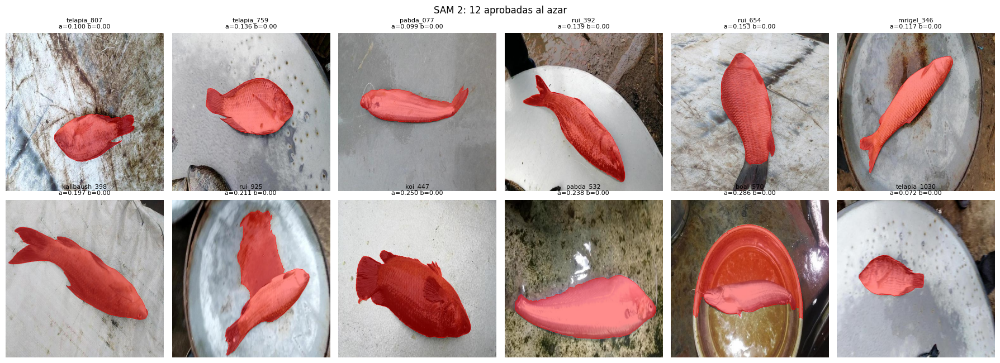

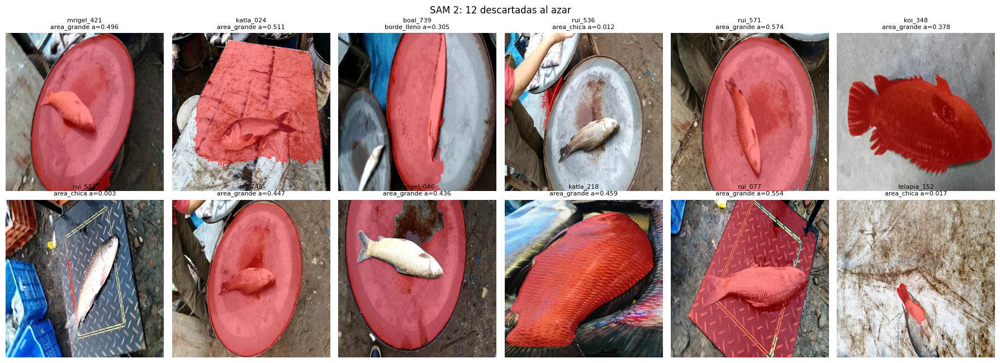

In [31]:
aprob = qc[qc['sam2_qc_ok']]
descar = qc[~qc['sam2_qc_ok']]
cuadricula_mascaras(aprob.sample(min(12, len(aprob)), random_state=SEMILLA), 'final', 'SAM 2: 12 aprobadas al azar', 'sam2_qc_aprobadas.png',
                    extra=lambda r: f'{r.stem}\na={r.area_frac:.3f} b={r.borde_frac:.2f}')
cuadricula_mascaras(descar.sample(min(12, len(descar)), random_state=SEMILLA), 'final', 'SAM 2: 12 descartadas al azar', 'sam2_qc_descartadas.png',
                    extra=lambda r: f'{r.stem}\n{r.motivo} a={r.area_frac:.3f}')

## 7. Comparación visual de calidad de etiqueta (sin IoU)

Ahora vamos a comparar a ojo, sobre las mismas 30 imágenes de val, GrabCut (contorno amarillo) contra la máscara final de SAM 2 (contorno verde). El título de cada fila trae el id, el estrato y si cada método pasa su control de calidad.

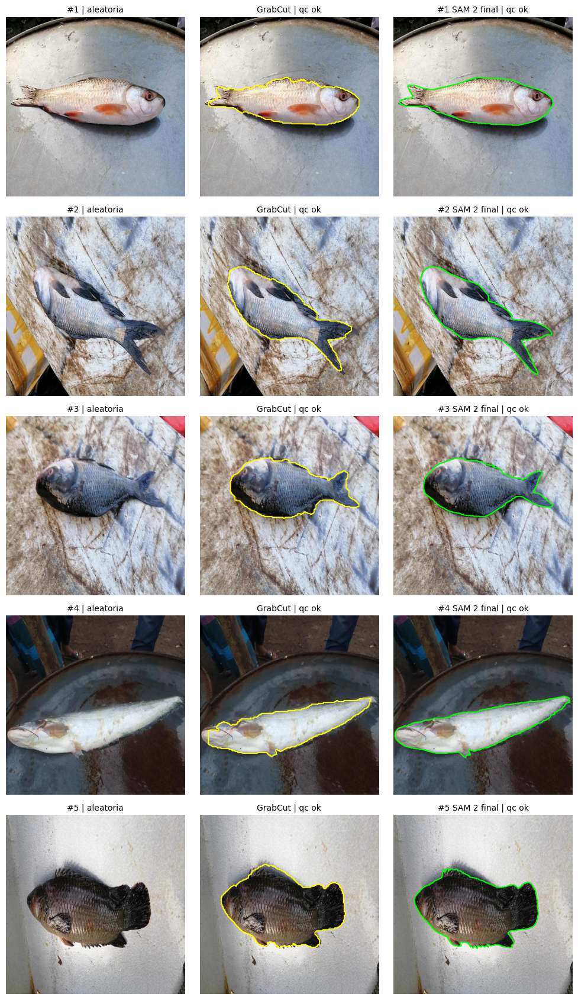

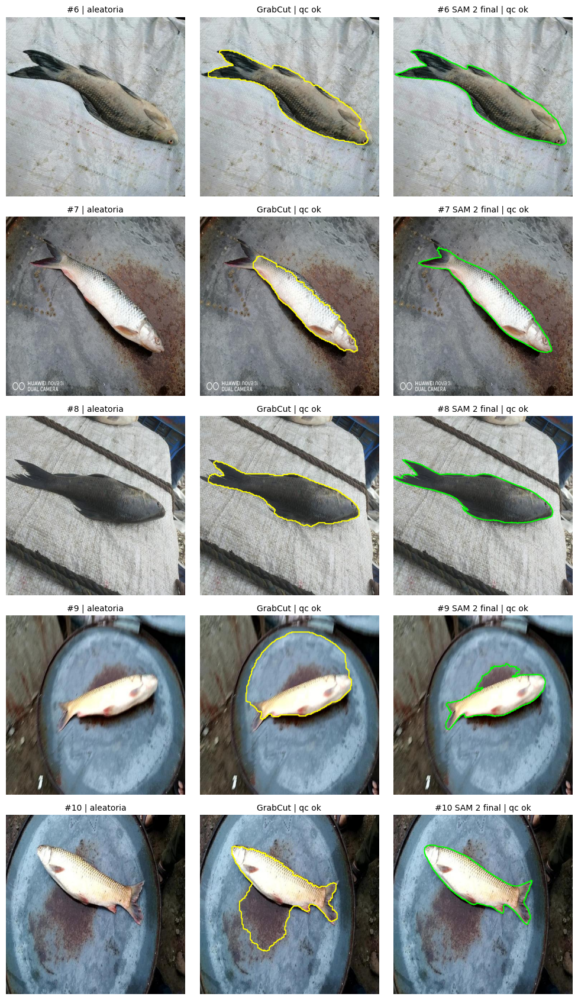

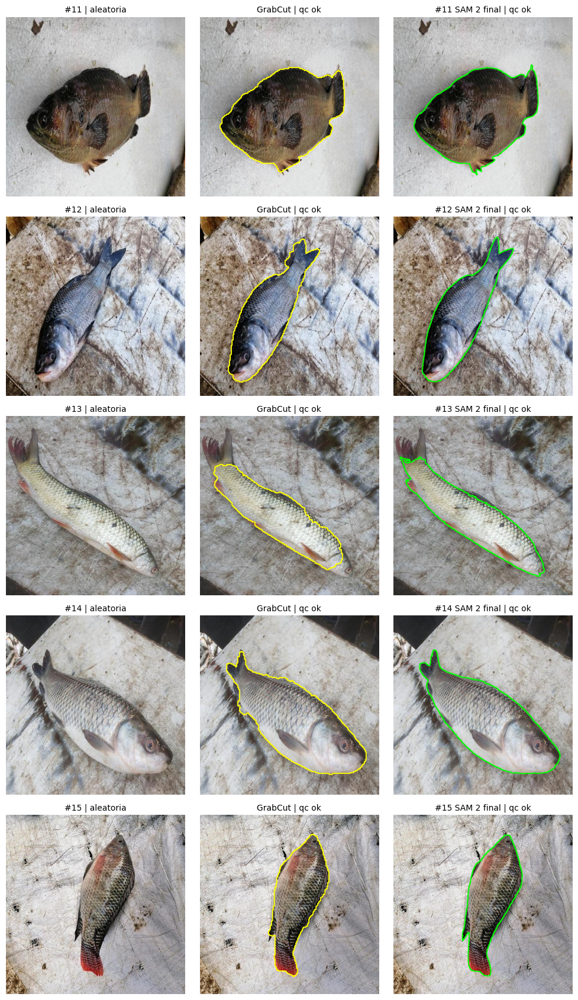

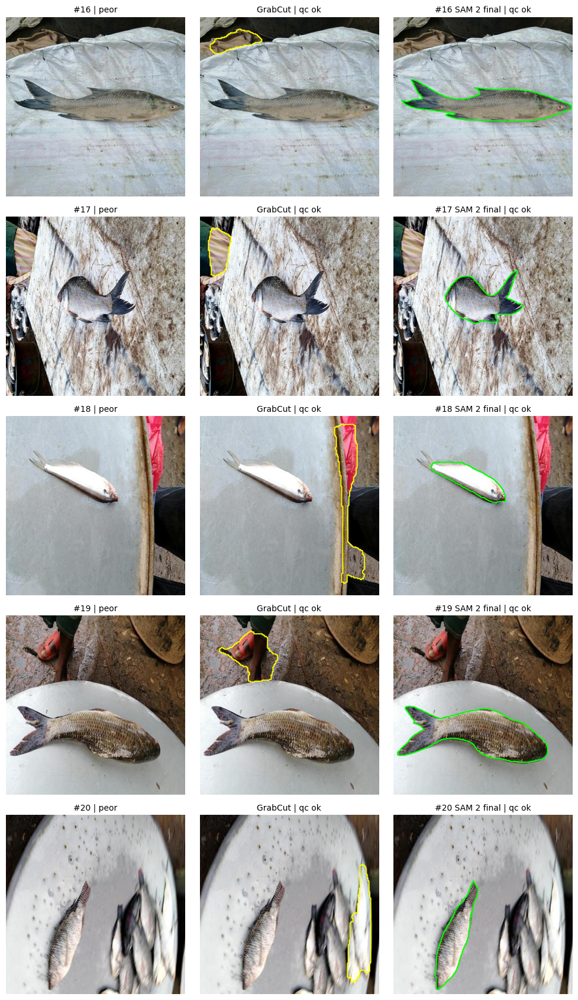

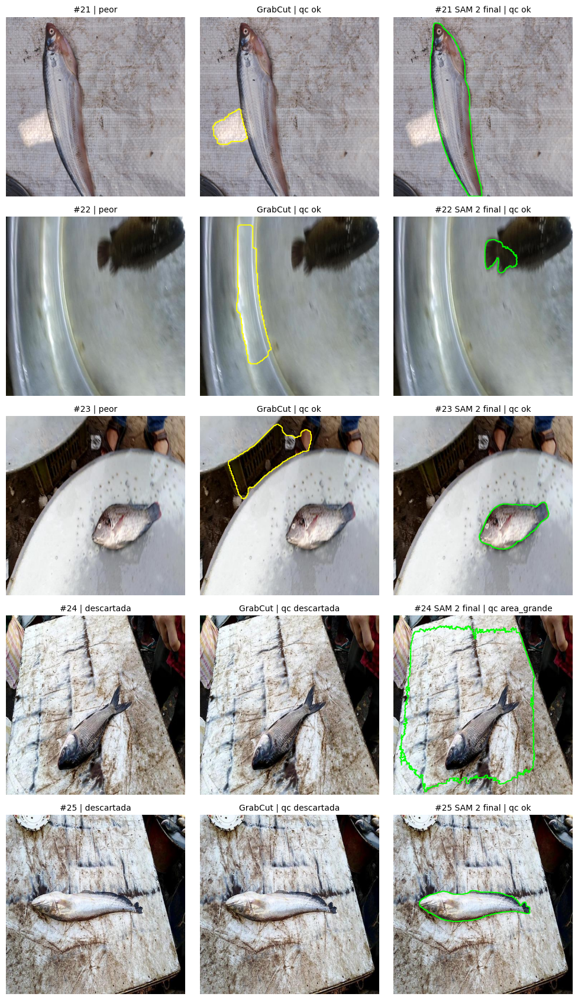

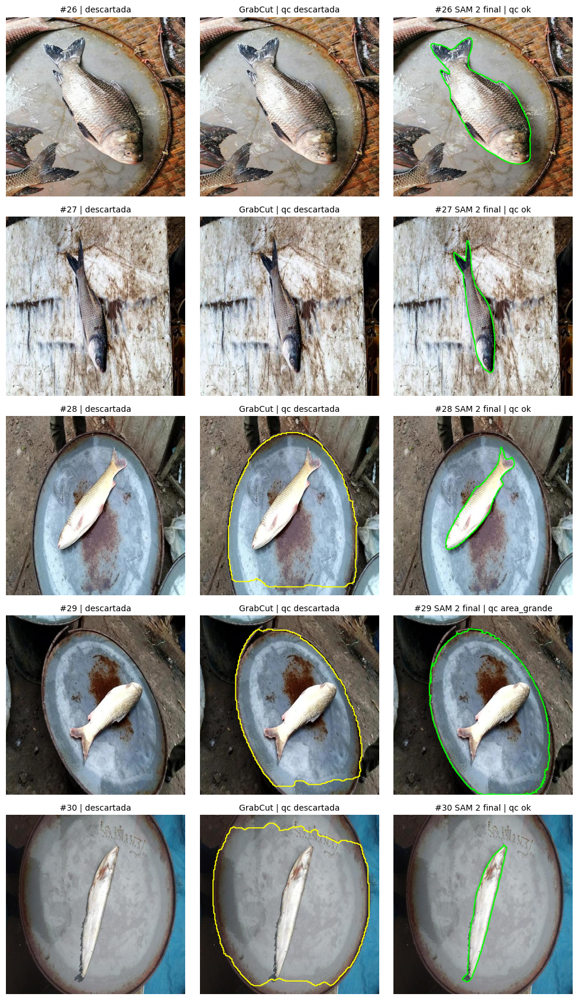

In [32]:
qc_idx = qc.set_index('filepath')  # SAM 2: motivo por filepath
gc_idx = qc_gc.set_index('filepath')  # GrabCut: qc_ok por filepath
VERDE = (0, 255, 0)

def cuadricula_comparacion(sub, archivo):  # original | GrabCut | SAM 2 final
    fig, axs = plt.subplots(len(sub), 3, figsize=(10, 3.4 * len(sub)), squeeze=False)
    for i, r in enumerate(sub.itertuples(index=False)):
        img = leer_rgb(r.filepath)
        sam = leer_mascara('final', r.carpeta, r.stem)
        mot = qc_idx.loc[r.filepath, 'motivo']
        vistas = [(img, f'#{r.id} | {r.estrato}'),
                  (contorno_sobre(img, leer_gc(r.stem), COL['GC']), f"GrabCut | qc {'ok' if gc_idx.loc[r.filepath, 'qc_ok'] else 'descartada'}"),
                  (contorno_sobre(img, sam, VERDE), f'#{r.id} SAM 2 final | qc {mot}')]
        for j, (im, tit) in enumerate(vistas):
            axs[i, j].imshow(im); axs[i, j].set_title(tit, fontsize=10); axs[i, j].axis('off')
    plt.tight_layout()
    plt.savefig(f'{FIG}/{archivo}', dpi=90)
    plt.show(); plt.close(fig)

assert set(muestra['filepath']) <= set(qc['filepath']), 'las 30 imágenes de val deben estar procesadas'
for pag, ini in enumerate(range(0, len(muestra), 5), 1):
    cuadricula_comparacion(muestra.iloc[ini:ini + 5], f'sam2_etiquetas_comparacion_p{pag}.png')

Ahora vamos a registrar tu comparación. En `CALIF_ETIQ` pega los ids (1 a 30) donde SAM 2 está **mejor**, **igual** o **peor** que GrabCut; cada id va en exactamente una lista. La celda cuenta por estrato y guarda `reports/tables/sam2_etiquetas_visual.json`. La decisión se toma así:

- **Bien**: SAM 2 mejor que peor en los tres estratos **y** la retención sube más de `RETENCION_PARECIDA_PP` puntos: seguir al cuaderno C.
- **Regular**: mejora solo en algunos estratos (por ejemplo aleatoria y peor) o la retención es parecida: seguir sin prometer menos sesgo de selección.
- **Mal**: en total no supera a GrabCut a ojo: parar y reportar como no adoptado.

`RETENCION_PARECIDA_PP` es un criterio operativo ajustable (puntos porcentuales dentro de los cuales la retención se considera parecida).

In [33]:
CALIF_ETIQ = {'sam2_mejor': [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30], 'igual': [], 'sam2_peor': []}  # pega aquí los ids (1..30)
RETENCION_PARECIDA_PP = 2.0  # AJUSTABLE: diferencia en puntos porcentuales que se considera "parecida"

asign = {}
for k, ids in CALIF_ETIQ.items():
    for i in ids:
        asign.setdefault(i, []).append(k)
faltan = sorted(set(range(1, 31)) - set(asign))
dup = sorted(i for i, v in asign.items() if len(v) > 1)
fuera = sorted(i for i in asign if i not in range(1, 31))
assert not (faltan or dup or fuera), f'faltan {faltan} | repetidos {dup} | fuera de 1..30 {fuera}'

ev = muestra[['id', 'estrato']].copy()
ev['categoria'] = ev['id'].map(lambda i: asign[i][0])
cnt = pd.crosstab(ev['estrato'], ev['categoria']).reindex(index=['aleatoria', 'peor', 'descartada'], columns=['sam2_mejor', 'igual', 'sam2_peor'], fill_value=0)
print(cnt)
tot = cnt.sum()
print(f"\nTotal: SAM 2 mejor {tot['sam2_mejor']} | igual {tot['igual']} | SAM 2 peor {tot['sam2_peor']}")
mejora_est = {e: bool(cnt.loc[e, 'sam2_mejor'] > cnt.loc[e, 'sam2_peor']) for e in cnt.index}
dif_ret = ret_sam2_pct - ret_gc_pct
print('Mejora por estrato (mejor > peor):', mejora_est)
print(f'Retención: SAM 2 {ret_sam2_pct:.1f} % vs GrabCut {ret_gc_pct:.1f} % (diferencia {dif_ret:+.1f} puntos)')

if tot['sam2_mejor'] <= tot['sam2_peor']:
    decision = 'Mal'
    print('\nMAL: no supera a GrabCut a ojo. Parar y reportar como no adoptado.')
elif all(mejora_est.values()) and dif_ret > RETENCION_PARECIDA_PP:
    decision = 'Bien'
    print('\nBIEN: SAM 2 mejora en los estratos y la retención sube. Seguir al cuaderno C.')
else:
    decision = 'Regular'
    print('\nREGULAR: seguir al cuaderno C sin prometer menos sesgo de selección.')

guardar_json_atomico({'ids': CALIF_ETIQ, 'conteos_por_estrato': {e: {k: int(cnt.loc[e, k]) for k in cnt.columns} for e in cnt.index},
                      'conteos_total': {k: int(tot[k]) for k in cnt.columns}, 'mejora_por_estrato': mejora_est,
                      'retencion_sam2_pct': ret_sam2_pct, 'retencion_grabcut_pct': ret_gc_pct, 'retencion_parecida_pp': RETENCION_PARECIDA_PP,
                      'decision': decision, 'prompt': PROMPT, 'checkpoint': CKPT_NAME},
                     f'{TAB}/sam2_etiquetas_visual.json')
print('Guardado: reports/tables/sam2_etiquetas_visual.json')

categoria   sam2_mejor  igual  sam2_peor
estrato                                 
aleatoria           15      0          0
peor                 8      0          0
descartada           7      0          0

Total: SAM 2 mejor 30 | igual 0 | SAM 2 peor 0
Mejora por estrato (mejor > peor): {'aleatoria': True, 'peor': True, 'descartada': True}
Retención: SAM 2 97.0 % vs GrabCut 79.3 % (diferencia +17.6 puntos)

BIEN: SAM 2 mejora en los estratos y la retención sube. Seguir al cuaderno C.
Guardado: reports/tables/sam2_etiquetas_visual.json


## 8. Empaquetar `masks_sam2.zip`

Ahora vamos a empaquetar todas las máscaras finales en `sam2/masks_sam2.zip` con `ZIP_DEFLATED` y entradas `<clase>/<stem>.png`. Se arma primero en local y se copia a Drive de forma atómica; si el zip ya existe con exactamente las mismas entradas, no se rehace. Incluye **todas** las máscaras posprocesadas: el filtro se aplica después con `sam2_mask_qc.csv`.

In [34]:
RUTA_ZIP = f'{SAM2_DIR}/masks_sam2.zip'
esperado_zip = {f'{r.carpeta}/{r.stem}.png' for r in lote.itertuples(index=False)}  # entradas <clase>/<stem>.png
assert len(esperado_zip) == len(lote)

reutilizar = False
if os.path.exists(RUTA_ZIP) and not REHACER_POSPROCESO:
    try:
        with zipfile.ZipFile(RUTA_ZIP) as z:
            reutilizar = set(z.namelist()) == esperado_zip
    except zipfile.BadZipFile:
        reutilizar = False
if reutilizar:
    print('masks_sam2.zip ya existe con las entradas esperadas: no se rehace.')
else:
    zip_local = '/content/masks_sam2.zip'
    with zipfile.ZipFile(zip_local, 'w', zipfile.ZIP_DEFLATED) as z:
        for arc in tqdm(sorted(esperado_zip), desc='zip'):
            c, nom = arc.split('/')
            z.write(ruta_lectura('final', c, nom[:-4]), arcname=arc)  # local si existe; si no, Drive
    copiar_atomico(zip_local, RUTA_ZIP)  # copia atómica a Drive
    print('Escrito', RUTA_ZIP, f'{os.path.getsize(RUTA_ZIP) / 1e6:.1f} MB')

zip:   0%|          | 0/8975 [00:00<?, ?it/s]

Escrito /content/drive/MyDrive/sylfish/sam2/masks_sam2.zip 16.5 MB


Ahora vamos a verificar el zip: número de entradas, nombres sin duplicados, integridad y tres máscaras al azar (semilla 42).

In [35]:
with zipfile.ZipFile(RUTA_ZIP) as z:
    nombres_z = z.namelist()
    assert len(nombres_z) == len(set(nombres_z)) == len(esperado_zip), f'entradas {len(nombres_z)} vs esperadas {len(esperado_zip)}'
    assert set(nombres_z) == esperado_zip, 'los nombres del zip no coinciden con <clase>/<stem>.png'
    assert z.testzip() is None, 'el zip tiene entradas dañadas'
    for nom in random.Random(SEMILLA).sample(sorted(nombres_z), 3):  # tres entradas al azar
        m = cv2.imdecode(np.frombuffer(z.read(nom), np.uint8), cv2.IMREAD_GRAYSCALE)
        assert m is not None and m.shape == (500, 500) and set(np.unique(m)) <= {0, 255}, f'entrada inválida: {nom}'
        print(f'{nom}: forma {m.shape}, valores {np.unique(m)}, área {np.mean(m > 0):.3f}')
print(f'OK: {len(nombres_z)} entradas en masks_sam2.zip, estructura <clase>/<stem>.png.')

kalibaush/kalibaush_152.png: forma (500, 500), valores [  0 255], área 0.186
boal/boal_411.png: forma (500, 500), valores [  0 255], área 0.174
mrigel/mrigel_328.png: forma (500, 500), valores [  0 255], área 0.157
OK: 8975 entradas en masks_sam2.zip, estructura <clase>/<stem>.png.
